# Deteksi Tuberkulosis (TB) dari Chest X-ray dengan CNN Dasar (Tanpa Transfer Learning)

> **Kelompok E** — Model Classification: CNN dari Scratch
>
> Notebook ini mengimplementasikan model CNN dasar tanpa transfer learning
> untuk klasifikasi Normal vs TB pada gambar Chest X-ray.
>
> **Arsitektur:**
> - 4 Convolutional Blocks (32 → 64 → 128 → 256 filters)
> - BatchNormalization + ReLU + MaxPooling pada setiap block
> - AdaptiveAvgPool(2×2) → Flatten(1024)
> - Dense(512) → Dense(256) → Dense(2, Softmax)
>
> **Catatan:** Notebook ini menggunakan data split yang sama (train/val/test CSV)
> dari notebook transfer learning untuk memastikan perbandingan yang fair.

---
## 1. Setup & Konfigurasi

In [1]:
# ============================================================
# 1.1 Mount Google Drive (untuk akses dataset)
# ============================================================
import os

IN_COLAB = 'COLAB_GPU' in os.environ or 'COLAB_RELEASE_TAG' in os.environ

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    print('Google Drive mounted.')
else:
    print('Not running in Colab. Using local paths.')

# Install openpyxl jika perlu
try:
    import openpyxl
    print('openpyxl ready.')
except ImportError:
    import subprocess
    subprocess.check_call(['pip', 'install', 'openpyxl', '-q'])
    print('openpyxl installed.')


Not running in Colab. Using local paths.
openpyxl ready.


In [2]:
# ============================================================
# 1.2 Import Libraries
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import cv2
import json
import warnings
import random
from pathlib import Path
from collections import Counter

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.metrics import AUC, Precision, Recall
from tensorflow.keras.optimizers import Adam

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_curve, auc,
    precision_recall_curve, f1_score, accuracy_score
)
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings('ignore')
print('All libraries imported successfully.')


All libraries imported successfully.


In [3]:
# ============================================================
# 1.3 Konfigurasi Global
# ============================================================

# --- Random Seed ---
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)
random.seed(RANDOM_SEED)
os.environ['PYTHONHASHSEED'] = str(RANDOM_SEED)

# --- Model & Training ---
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 50              # Single-stage training (no transfer learning)
LEARNING_RATE = 5e-4     # FIX: Dinaikkan dari 1e-4 — CNN from-scratch butuh LR lebih tinggi

# --- Path ---
if IN_COLAB:
    BASE_DIR = Path('/content/drive/MyDrive/Deteksi Tuberkulosis (TB)')
else:
    BASE_DIR = Path(r'c:\Users\Monk\Downloads\Deteksi Tuberkulosis (TB)')

# Sub-directories
MENDELEY_DIR = BASE_DIR / 'Mendeley'
KAGGLE_DIR = BASE_DIR / 'Kaggle'
OUTPUT_DIR = BASE_DIR / 'outputs'
OUTPUT_DIR.mkdir(exist_ok=True)

print(f'BASE_DIR: {BASE_DIR}')
print(f'BASE_DIR exists: {BASE_DIR.exists()}')
print(f'IMG_SIZE: {IMG_SIZE}')
print(f'BATCH_SIZE: {BATCH_SIZE}')
print(f'EPOCHS: {EPOCHS}')
print(f'LEARNING_RATE: {LEARNING_RATE}')

# --- Data Cleaning ---
LAPLACIAN_THRESHOLD = 50.0


BASE_DIR: c:\Users\Monk\Downloads\Deteksi Tuberkulosis (TB)
BASE_DIR exists: True
IMG_SIZE: (224, 224)
BATCH_SIZE: 32
EPOCHS: 50
LEARNING_RATE: 0.0005


In [4]:
# ============================================================
# 1.4 Checkpoint: Versi Library & GPU
# ============================================================
print(f'TensorFlow : {tf.__version__}')
print(f'Keras      : {keras.__version__}')
print(f'NumPy      : {np.__version__}')
print(f'Pandas     : {pd.__version__}')

# GPU Check
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f'\nGPU tersedia: {len(gpus)}')
    for gpu in gpus:
        print(f'  {gpu}')
    # Enable memory growth
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
else:
    print('\n⚠ Tidak ada GPU. Training akan lambat!')

print(f'\nDevice: {tf.test.gpu_device_name() or "CPU"}')


TensorFlow : 2.21.0
Keras      : 3.14.1
NumPy      : 2.3.3
Pandas     : 2.3.2

⚠ Tidak ada GPU. Training akan lambat!

Device: CPU


In [5]:
# ============================================================
# 2.1 Definisi Path Dataset
# ============================================================

# Mendeley paths
MENDELEY_NORMAL_DIR = MENDELEY_DIR / 'Normal Chest X-rays'
MENDELEY_TB_DIR = MENDELEY_DIR / 'TB Chest X-rays'

# Kaggle paths
KAGGLE_NORMAL_DIR = KAGGLE_DIR / 'Normal'
KAGGLE_TB_DIR = KAGGLE_DIR / 'Tuberculosis'

# Kaggle metadata paths
KAGGLE_NORMAL_META = KAGGLE_DIR / 'Normal.metadata.xlsx'
KAGGLE_TB_META = KAGGLE_DIR / 'Tuberculosis.metadata.xlsx'

# Verifikasi semua path
paths_to_check = {
    'Mendeley Normal': MENDELEY_NORMAL_DIR,
    'Mendeley TB': MENDELEY_TB_DIR,
    'Kaggle Normal': KAGGLE_NORMAL_DIR,
    'Kaggle TB': KAGGLE_TB_DIR,
    'Kaggle Normal Metadata': KAGGLE_NORMAL_META,
    'Kaggle TB Metadata': KAGGLE_TB_META,
}

for name, path in paths_to_check.items():
    status = '✓' if path.exists() else '✗ NOT FOUND'
    print(f'  {status}  {name}: {path}')


  ✓  Mendeley Normal: c:\Users\Monk\Downloads\Deteksi Tuberkulosis (TB)\Mendeley\Normal Chest X-rays
  ✓  Mendeley TB: c:\Users\Monk\Downloads\Deteksi Tuberkulosis (TB)\Mendeley\TB Chest X-rays
  ✓  Kaggle Normal: c:\Users\Monk\Downloads\Deteksi Tuberkulosis (TB)\Kaggle\Normal
  ✓  Kaggle TB: c:\Users\Monk\Downloads\Deteksi Tuberkulosis (TB)\Kaggle\Tuberculosis
  ✓  Kaggle Normal Metadata: c:\Users\Monk\Downloads\Deteksi Tuberkulosis (TB)\Kaggle\Normal.metadata.xlsx
  ✓  Kaggle TB Metadata: c:\Users\Monk\Downloads\Deteksi Tuberkulosis (TB)\Kaggle\Tuberculosis.metadata.xlsx


In [6]:
# ============================================================
# 2.2 Baca Metadata Excel Kaggle (untuk sub_source)
# ============================================================

def read_kaggle_metadata(meta_path):
    """Baca metadata Excel Kaggle dan ekstrak sub_source dari URL."""
    df = pd.read_excel(meta_path, engine='openpyxl')
    
    # Map URL ke sub_source
    def url_to_subsource(url):
        if url is None:
            return 'unknown'
        url = str(url).lower()
        if 'tuberculosis.by' in url:
            return 'belarus'
        elif 'ncbi.nlm.nih.gov' in url:
            return 'nlm'
        elif 'rsna' in url or 'pneumonia' in url:
            return 'rsna'
        elif 'niaid' in url or 'tbportals' in url:
            return 'niaid'
        else:
            return 'other'
    
    df['sub_source'] = df['URL'].apply(url_to_subsource)
    # Buat mapping filename -> sub_source
    mapping = dict(zip(df['FILE NAME'], df['sub_source']))
    return mapping

# Baca metadata
kaggle_normal_subsource = read_kaggle_metadata(KAGGLE_NORMAL_META)
kaggle_tb_subsource = read_kaggle_metadata(KAGGLE_TB_META)

print('Kaggle Normal sub-source distribution:')
print(pd.Series(kaggle_normal_subsource.values()).value_counts().to_string())
print()
print('Kaggle TB sub-source distribution:')
print(pd.Series(kaggle_tb_subsource.values()).value_counts().to_string())


Kaggle Normal sub-source distribution:
rsna    3094
nlm      406

Kaggle TB sub-source distribution:
nlm        394
belarus    306


In [7]:
# ============================================================
# 2.3 Build Dataframe Metadata
# ============================================================

def build_metadata_df():
    """Scan semua gambar dan bangun dataframe metadata."""
    records = []
    
    # --- Mendeley Normal ---
    for fpath in sorted(MENDELEY_NORMAL_DIR.glob('*')):
        if fpath.suffix.lower() in ['.jpg', '.jpeg', '.png']:
            records.append({
                'filepath': str(fpath),
                'label': 'Normal',
                'source': 'mendeley',
                'sub_source': 'mendeley_single',
                'format': fpath.suffix.lower().replace('.', ''),
                'original_filename': fpath.name,
            })
    
    # --- Mendeley TB ---
    for fpath in sorted(MENDELEY_TB_DIR.glob('*')):
        if fpath.suffix.lower() in ['.jpg', '.jpeg', '.png']:
            records.append({
                'filepath': str(fpath),
                'label': 'TB',
                'source': 'mendeley',
                'sub_source': 'mendeley_single',
                'format': fpath.suffix.lower().replace('.', ''),
                'original_filename': fpath.name,
            })
    
    # --- Kaggle Normal ---
    for fpath in sorted(KAGGLE_NORMAL_DIR.glob('*')):
        if fpath.suffix.lower() in ['.jpg', '.jpeg', '.png']:
            fname_no_ext = fpath.stem  # e.g. 'Normal-1'
            sub_src = kaggle_normal_subsource.get(fname_no_ext, 'unknown')
            records.append({
                'filepath': str(fpath),
                'label': 'Normal',
                'source': 'kaggle',
                'sub_source': sub_src,
                'format': fpath.suffix.lower().replace('.', ''),
                'original_filename': fpath.name,
            })
    
    # --- Kaggle TB ---
    for fpath in sorted(KAGGLE_TB_DIR.glob('*')):
        if fpath.suffix.lower() in ['.jpg', '.jpeg', '.png']:
            fname_no_ext = fpath.stem  # e.g. 'Tuberculosis-1'
            sub_src = kaggle_tb_subsource.get(fname_no_ext, 'unknown')
            records.append({
                'filepath': str(fpath),
                'label': 'TB',
                'source': 'kaggle',
                'sub_source': sub_src,
                'format': fpath.suffix.lower().replace('.', ''),
                'original_filename': fpath.name,
            })
    
    df = pd.DataFrame(records)
    return df

df_raw = build_metadata_df()
print(f'Total gambar ditemukan: {len(df_raw)}')
print()
print('Distribusi per source × label:')
print(df_raw.groupby(['source', 'label']).size().unstack(fill_value=0))
print()
print('Distribusi per sub_source × label:')
print(df_raw.groupby(['sub_source', 'label']).size().unstack(fill_value=0))


Total gambar ditemukan: 7208

Distribusi per source × label:
label     Normal    TB
source                
kaggle      3500   700
mendeley     514  2494

Distribusi per sub_source × label:
label            Normal    TB
sub_source                   
belarus               0   306
mendeley_single     514  2494
nlm                 406   394
rsna               3094     0


In [8]:
# ============================================================
# 2.4 Baca Resolusi Gambar (width × height)
# ============================================================
# Ini membutuhkan waktu beberapa menit untuk ~7000 gambar

print('Membaca resolusi gambar... (ini mungkin memakan waktu beberapa menit)')

widths = []
heights = []
read_errors = []

for idx, row in df_raw.iterrows():
    img = cv2.imread(row['filepath'])
    if img is not None:
        h, w = img.shape[:2]
        widths.append(w)
        heights.append(h)
    else:
        widths.append(None)
        heights.append(None)
        read_errors.append(row['filepath'])
    
    if (idx + 1) % 1000 == 0:
        print(f'  Processed {idx + 1}/{len(df_raw)} gambar...')

df_raw['width'] = widths
df_raw['height'] = heights

print(f'\nSelesai. Gambar corrupt/tidak terbaca: {len(read_errors)}')
if read_errors:
    print('File bermasalah:')
    for f in read_errors[:10]:
        print(f'  - {f}')


Membaca resolusi gambar... (ini mungkin memakan waktu beberapa menit)
  Processed 1000/7208 gambar...
  Processed 2000/7208 gambar...
  Processed 3000/7208 gambar...
  Processed 4000/7208 gambar...
  Processed 5000/7208 gambar...
  Processed 6000/7208 gambar...
  Processed 7000/7208 gambar...

Selesai. Gambar corrupt/tidak terbaca: 0


In [9]:
# ============================================================
# 2.5 Checkpoint: Validasi Jumlah File
# ============================================================
print('=' * 60)
print('CHECKPOINT: Data Acquisition & Loading')
print('=' * 60)
print(f'Total gambar: {len(df_raw)}')
print(f'Gambar corrupt: {len(read_errors)}')
print()
print('Distribusi per source × label:')
dist = df_raw.groupby(['source', 'label']).size().unstack(fill_value=0)
dist['Total'] = dist.sum(axis=1)
dist.loc['Total'] = dist.sum()
print(dist.to_string())
print()
print('Distribusi per sub_source:')
sub_dist = df_raw.groupby(['sub_source', 'label']).size().unstack(fill_value=0)
sub_dist['Total'] = sub_dist.sum(axis=1)
print(sub_dist.to_string())
print('=' * 60)


CHECKPOINT: Data Acquisition & Loading
Total gambar: 7208
Gambar corrupt: 0

Distribusi per source × label:
label     Normal    TB  Total
source                       
kaggle      3500   700   4200
mendeley     514  2494   3008
Total       4014  3194   7208

Distribusi per sub_source:
label            Normal    TB  Total
sub_source                          
belarus               0   306    306
mendeley_single     514  2494   3008
nlm                 406   394    800
rsna               3094     0   3094


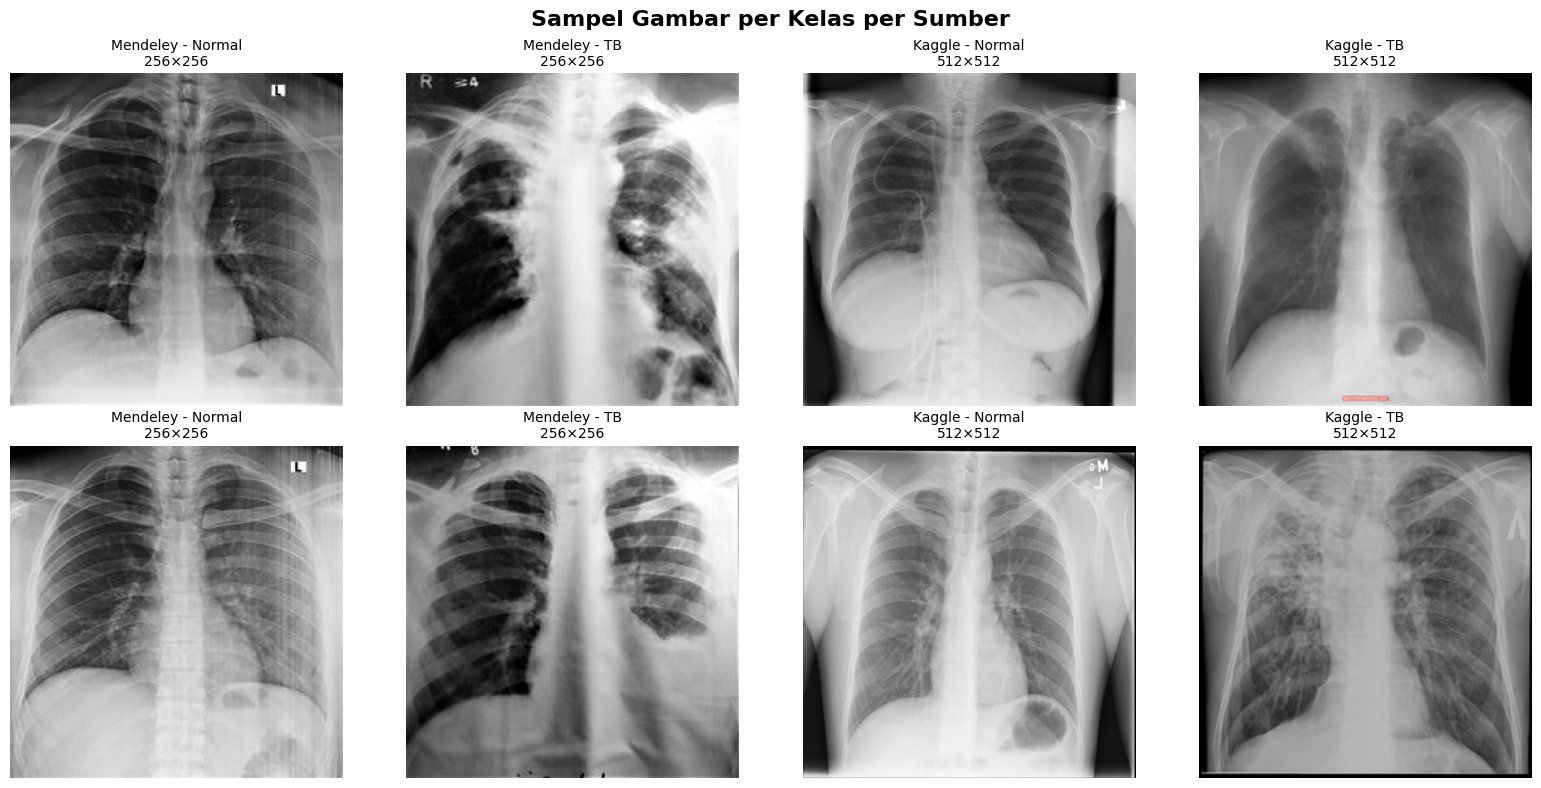

In [10]:
# ============================================================
# 3.1 Visualisasi Sampel Gambar per Kelas per Sumber
# ============================================================

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Sampel Gambar per Kelas per Sumber', fontsize=16, fontweight='bold')

combinations = [
    ('mendeley', 'Normal'), ('mendeley', 'TB'),
    ('kaggle', 'Normal'), ('kaggle', 'TB'),
]

for i, (source, label) in enumerate(combinations):
    subset = df_raw[(df_raw['source'] == source) & (df_raw['label'] == label)]
    samples = subset.sample(n=2, random_state=RANDOM_SEED)
    
    for j, (_, row) in enumerate(samples.iterrows()):
        ax = axes[j, i]
        img = cv2.imread(row['filepath'])
        if img is not None:
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            ax.imshow(img_rgb, cmap='gray')
        ax.set_title(f"{source.capitalize()} - {label}\n{row['width']}×{row['height']}", fontsize=10)
        ax.axis('off')

plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / 'sample_images.png'), dpi=150, bbox_inches='tight')
plt.show()


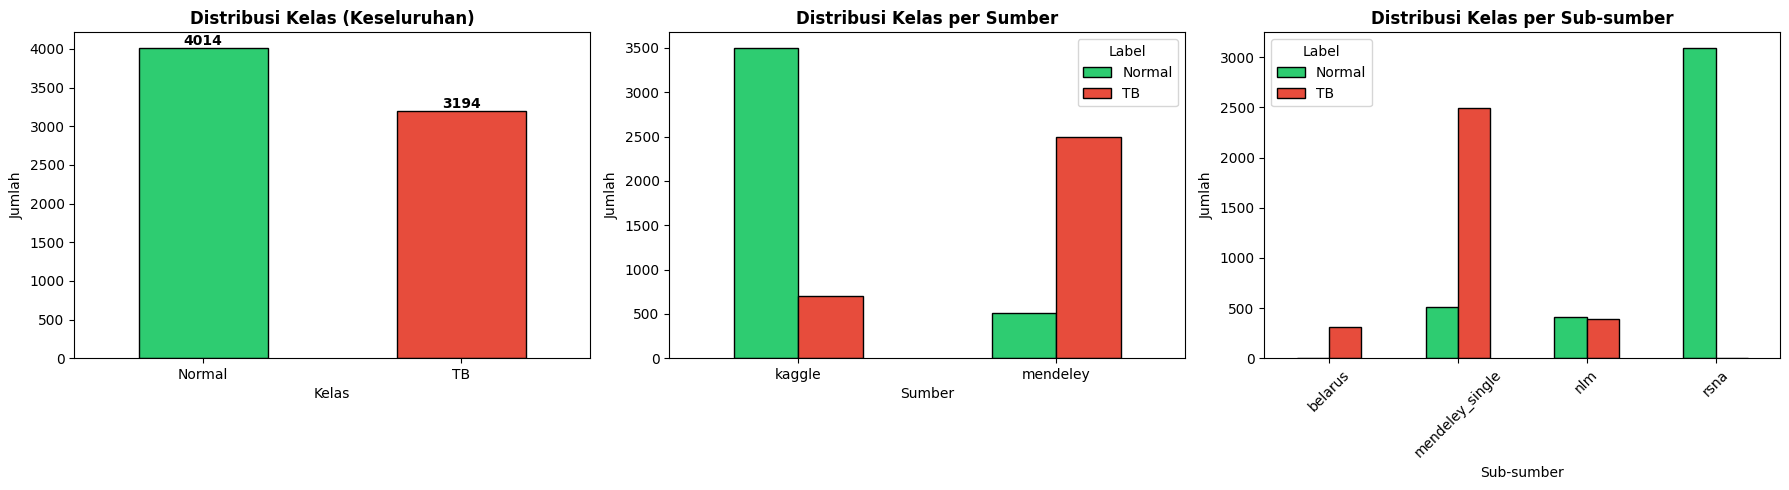

Rasio TB:Normal = 1:1.26


In [11]:
# ============================================================
# 3.2 Distribusi Kelas per Sumber (Bar Chart)
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Overall distribution
ax = axes[0]
df_raw['label'].value_counts().plot(kind='bar', ax=ax, color=['#2ecc71', '#e74c3c'], edgecolor='black')
ax.set_title('Distribusi Kelas (Keseluruhan)', fontweight='bold')
ax.set_xlabel('Kelas')
ax.set_ylabel('Jumlah')
ax.tick_params(axis='x', rotation=0)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
               ha='center', va='bottom', fontweight='bold')

# Plot 2: Per source
ax = axes[1]
ct = df_raw.groupby(['source', 'label']).size().unstack(fill_value=0)
ct.plot(kind='bar', ax=ax, color=['#2ecc71', '#e74c3c'], edgecolor='black')
ax.set_title('Distribusi Kelas per Sumber', fontweight='bold')
ax.set_xlabel('Sumber')
ax.set_ylabel('Jumlah')
ax.tick_params(axis='x', rotation=0)
ax.legend(title='Label')

# Plot 3: Per sub_source
ax = axes[2]
ct2 = df_raw.groupby(['sub_source', 'label']).size().unstack(fill_value=0)
ct2.plot(kind='bar', ax=ax, color=['#2ecc71', '#e74c3c'], edgecolor='black')
ax.set_title('Distribusi Kelas per Sub-sumber', fontweight='bold')
ax.set_xlabel('Sub-sumber')
ax.set_ylabel('Jumlah')
ax.tick_params(axis='x', rotation=45)
ax.legend(title='Label')

plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / 'class_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()

# Rasio kelas
n_normal = (df_raw['label'] == 'Normal').sum()
n_tb = (df_raw['label'] == 'TB').sum()
print(f'Rasio TB:Normal = 1:{n_normal/n_tb:.2f}')


### Penjelasan Rasio Kelas (TB vs Normal)
Pada awal pengumpulan data murni dari **Mendeley**, jumlah citra TB adalah 2.494 dan Normal 514 (Rasio 4.8 : 1). Namun setelah **Dataset Kaggle** ditambahkan (yang didominasi gambar Normal mencapai ~3.500 citra), jumlah total keseluruhan berbalik menjadi didominasi oleh kelas Normal. Hasil akhirnya membentuk rasio **TB : Normal = 1 : 1.26** (Artinya jumlah citra Normal 1,26x lebih banyak dari citra TB).

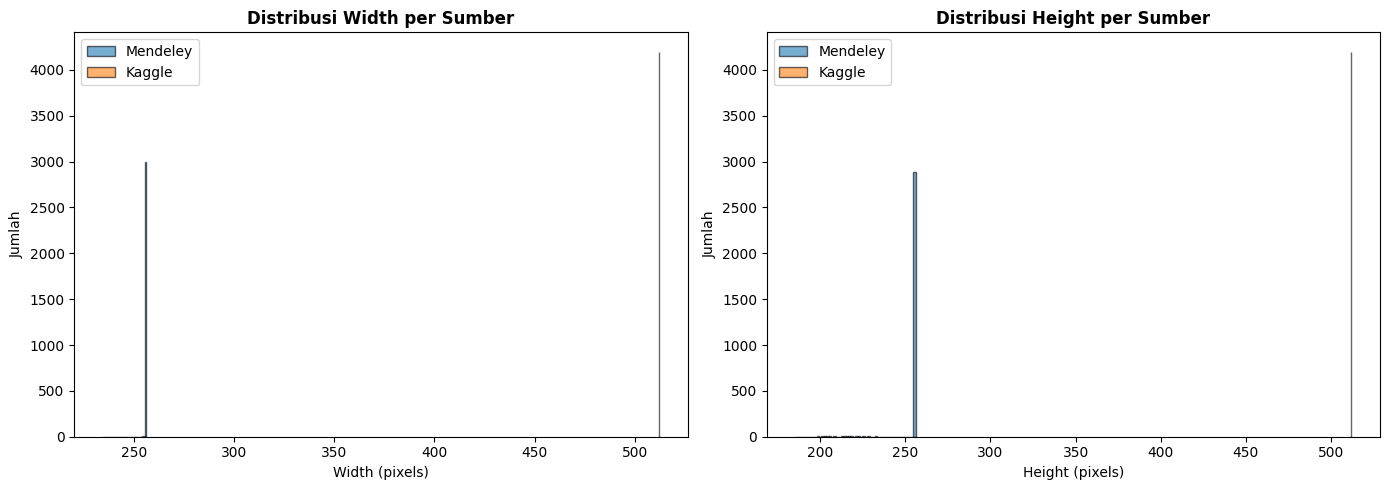

Statistik resolusi per sumber:
           width                                                           height                                                         
           count        mean       std    min    25%    50%    75%    max   count        mean       std    min    25%    50%    75%    max
source                                                                                                                                    
kaggle    4200.0  512.000000  0.000000  512.0  512.0  512.0  512.0  512.0  4200.0  512.000000  0.000000  512.0  512.0  512.0  512.0  512.0
mendeley  3008.0  255.975731  0.494475  234.0  256.0  256.0  256.0  256.0  3008.0  254.278258  8.572392  185.0  256.0  256.0  256.0  256.0


In [12]:
# ============================================================
# 3.3 Distribusi Resolusi per Sumber
# ============================================================

df_valid = df_raw.dropna(subset=['width', 'height']).copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, col in enumerate(['width', 'height']):
    ax = axes[i]
    for source in ['mendeley', 'kaggle']:
        subset = df_valid[df_valid['source'] == source]
        ax.hist(subset[col], bins=50, alpha=0.6, label=source.capitalize(), edgecolor='black')
    ax.set_title(f'Distribusi {col.capitalize()} per Sumber', fontweight='bold')
    ax.set_xlabel(col.capitalize() + ' (pixels)')
    ax.set_ylabel('Jumlah')
    ax.legend()

plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / 'resolution_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()

print('Statistik resolusi per sumber:')
print(df_valid.groupby('source')[['width', 'height']].describe().to_string())


Menghitung Laplacian variance untuk deteksi blur...
  Processed 1000/7208...
  Processed 2000/7208...
  Processed 3000/7208...
  Processed 4000/7208...
  Processed 5000/7208...
  Processed 6000/7208...
  Processed 7000/7208...


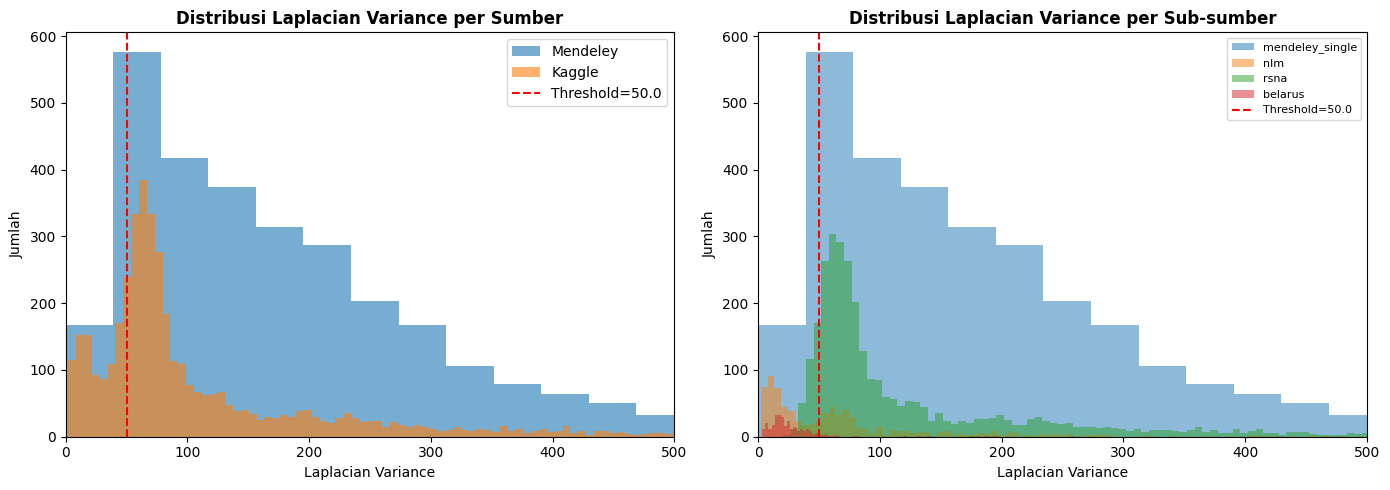

In [13]:
# ============================================================
# 3.4 Deteksi Gambar Blur (Laplacian Variance)
# ============================================================

print('Menghitung Laplacian variance untuk deteksi blur...')

laplacian_vars = []
for idx, row in df_valid.iterrows():
    img = cv2.imread(row['filepath'], cv2.IMREAD_GRAYSCALE)
    if img is not None:
        lap_var = cv2.Laplacian(img, cv2.CV_64F).var()
        laplacian_vars.append(lap_var)
    else:
        laplacian_vars.append(None)
    
    if (idx + 1) % 1000 == 0:
        print(f'  Processed {idx + 1}/{len(df_valid)}...')

df_valid['laplacian_var'] = laplacian_vars
df_raw = df_raw.merge(
    df_valid[['filepath', 'laplacian_var']], on='filepath', how='left'
)

# Visualisasi distribusi Laplacian variance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for source in ['mendeley', 'kaggle']:
    subset = df_raw[df_raw['source'] == source].dropna(subset=['laplacian_var'])
    ax.hist(subset['laplacian_var'], bins=100, alpha=0.6, label=source.capitalize())
ax.axvline(x=LAPLACIAN_THRESHOLD, color='red', linestyle='--', label=f'Threshold={LAPLACIAN_THRESHOLD}')
ax.set_title('Distribusi Laplacian Variance per Sumber', fontweight='bold')
ax.set_xlabel('Laplacian Variance')
ax.set_ylabel('Jumlah')
ax.set_xlim(0, 500)
ax.legend()

ax = axes[1]
for sub_src in df_raw['sub_source'].unique():
    subset = df_raw[df_raw['sub_source'] == sub_src].dropna(subset=['laplacian_var'])
    if len(subset) > 0:
        ax.hist(subset['laplacian_var'], bins=100, alpha=0.5, label=sub_src)
ax.axvline(x=LAPLACIAN_THRESHOLD, color='red', linestyle='--', label=f'Threshold={LAPLACIAN_THRESHOLD}')
ax.set_title('Distribusi Laplacian Variance per Sub-sumber', fontweight='bold')
ax.set_xlabel('Laplacian Variance')
ax.set_ylabel('Jumlah')
ax.set_xlim(0, 500)
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / 'blur_detection.png'), dpi=150, bbox_inches='tight')
plt.show()


In [14]:
# ============================================================
# 3.5 Checkpoint: Ringkasan Gambar Valid vs Dikecualikan
# ============================================================

# Tandai gambar blur
df_raw['is_blur'] = df_raw['laplacian_var'].apply(
    lambda x: True if (x is not None and x < LAPLACIAN_THRESHOLD) else False
)
df_raw['is_corrupt'] = df_raw['width'].isna()
df_raw['is_excluded'] = df_raw['is_corrupt']  # Tidak lagi mengecualikan gambar blur atas permintaan Anda

print('=' * 60)
print('CHECKPOINT: Sanity Check — Gambar Dikecualikan')
print('=' * 60)

# Per source
print('\nGambar blur (Laplacian < {}) per source × label:'.format(LAPLACIAN_THRESHOLD))
blur_counts = df_raw[df_raw['is_blur']].groupby(['source', 'label']).size()
print(blur_counts.to_string() if len(blur_counts) > 0 else '  Tidak ada gambar blur.')

# Per sub_source
print('\nGambar blur per sub_source × label:')
blur_sub = df_raw[df_raw['is_blur']].groupby(['sub_source', 'label']).size()
print(blur_sub.to_string() if len(blur_sub) > 0 else '  Tidak ada gambar blur.')

print(f'\nGambar corrupt: {df_raw["is_corrupt"].sum()}')
print(f'Total dikecualikan: {df_raw["is_excluded"].sum()}')
print(f'Total valid: {(~df_raw["is_excluded"]).sum()}')

# Peringatan jika pembuangan timpang
if len(blur_counts) > 0:
    print('\n⚠ PERHATIAN: Periksa apakah pembuangan gambar blur timpang ke satu sumber.')
    print('  Jika signifikan, pertimbangkan threshold lebih longgar untuk sub-sumber tertentu.')

print('=' * 60)


CHECKPOINT: Sanity Check — Gambar Dikecualikan

Gambar blur (Laplacian < 50.0) per source × label:
source    label 
kaggle    Normal    324
          TB        636
mendeley  TB        320

Gambar blur per sub_source × label:
sub_source       label 
belarus          TB        278
mendeley_single  TB        320
nlm              Normal     29
                 TB        358
rsna             Normal    295

Gambar corrupt: 0
Total dikecualikan: 0
Total valid: 7208

⚠ PERHATIAN: Periksa apakah pembuangan gambar blur timpang ke satu sumber.
  Jika signifikan, pertimbangkan threshold lebih longgar untuk sub-sumber tertentu.


In [15]:
# ============================================================
# 4.1 Filter Gambar Valid & Buat DataFrame Clean
# ============================================================

df_clean = df_raw[~df_raw['is_excluded']].copy().reset_index(drop=True)

# Encode label: Normal=0, TB=1
df_clean['label_encoded'] = (df_clean['label'] == 'TB').astype(int)

# Stratification key untuk splitting
df_clean['strat_key'] = df_clean['label'] + '_' + df_clean['source']

print(f'Dataset clean: {len(df_clean)} gambar')
print()
print('Distribusi per source × label (clean):')
clean_dist = df_clean.groupby(['source', 'label']).size().unstack(fill_value=0)
clean_dist['Total'] = clean_dist.sum(axis=1)
clean_dist.loc['Total'] = clean_dist.sum()
print(clean_dist.to_string())

# Simpan metadata clean
df_clean.to_csv(str(OUTPUT_DIR / 'metadata_clean.csv'), index=False)
print(f'\nMetadata clean disimpan ke: {OUTPUT_DIR / "metadata_clean.csv"}')


Dataset clean: 7208 gambar

Distribusi per source × label (clean):
label     Normal    TB  Total
source                       
kaggle      3500   700   4200
mendeley     514  2494   3008
Total       4014  3194   7208

Metadata clean disimpan ke: c:\Users\Monk\Downloads\Deteksi Tuberkulosis (TB)\outputs\metadata_clean.csv


In [16]:
# ============================================================
# 4.2 Checkpoint: Distribusi Setelah Cleaning
# ============================================================

print('=' * 60)
print('CHECKPOINT: Preprocessing — Dataset Clean')
print('=' * 60)
print(f'Total gambar clean: {len(df_clean)}')
print(f'Normal: {(df_clean["label"] == "Normal").sum()}')
print(f'TB:     {(df_clean["label"] == "TB").sum()}')
n_normal_c = (df_clean['label'] == 'Normal').sum()
n_tb_c = (df_clean['label'] == 'TB').sum()
print(f'Rasio TB:Normal = 1:{n_normal_c/n_tb_c:.2f}')
print()
print('Distribusi strat_key:')
print(df_clean['strat_key'].value_counts().to_string())
print('=' * 60)


CHECKPOINT: Preprocessing — Dataset Clean
Total gambar clean: 7208
Normal: 4014
TB:     3194
Rasio TB:Normal = 1:1.26

Distribusi strat_key:
strat_key
Normal_kaggle      3500
TB_mendeley        2494
TB_kaggle           700
Normal_mendeley     514


### Catatan Perubahan Rasio
Setelah pembuangan citra yang corrupt dan blur (laplacian filtering), rasio sedikit bergeser karena jumlah citra blur yang dibuang pada masing-masing kelas tidak persis sama. Jika kelas Normal memiliki lebih banyak citra buram yang dibuang, rasio `1 : 1.26` akan sedikit mengecil, namun dominasi kelas Normal tetap bertahan.

In [17]:
# ============================================================
# 5.1 Stratified Split: 70% Train / 15% Val / 15% Test
# ============================================================

# Tahap 1: train+val (85%) vs test (15%)
df_trainval, df_test = train_test_split(
    df_clean, test_size=0.15, random_state=RANDOM_SEED,
    stratify=df_clean['strat_key']
)

# Tahap 2: train (70/85 ≈ 82.35%) vs val (15/85 ≈ 17.65%) dari trainval
val_ratio = 0.15 / 0.85  # ≈ 0.1765
df_train, df_val = train_test_split(
    df_trainval, test_size=val_ratio, random_state=RANDOM_SEED,
    stratify=df_trainval['strat_key']
)

# Reset index
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

print(f'Train: {len(df_train)} ({len(df_train)/len(df_clean)*100:.1f}%)')
print(f'Val:   {len(df_val)} ({len(df_val)/len(df_clean)*100:.1f}%)')
print(f'Test:  {len(df_test)} ({len(df_test)/len(df_clean)*100:.1f}%)')
print(f'Total: {len(df_train) + len(df_val) + len(df_test)}')


Train: 5044 (70.0%)
Val:   1082 (15.0%)
Test:  1082 (15.0%)
Total: 7208


In [18]:
# ============================================================
# 5.2 Verifikasi: Tidak Ada Data Leakage
# ============================================================

train_files = set(df_train['filepath'])
val_files = set(df_val['filepath'])
test_files = set(df_test['filepath'])

assert len(train_files & val_files) == 0, 'DATA LEAKAGE: train ∩ val!'
assert len(train_files & test_files) == 0, 'DATA LEAKAGE: train ∩ test!'
assert len(val_files & test_files) == 0, 'DATA LEAKAGE: val ∩ test!'
print('✓ Tidak ada data leakage antar split.')


✓ Tidak ada data leakage antar split.


In [19]:
# ============================================================
# 5.3 Simpan Split ke CSV & Tabel Kontingensi
# ============================================================

df_train.to_csv(str(OUTPUT_DIR / 'train.csv'), index=False)
df_val.to_csv(str(OUTPUT_DIR / 'val.csv'), index=False)
df_test.to_csv(str(OUTPUT_DIR / 'test.csv'), index=False)
print('Split CSV saved to outputs/')

# Tabel kontingensi per split
print('\n' + '=' * 60)
print('CHECKPOINT: Data Splitting')
print('=' * 60)

for name, df_split in [('TRAIN', df_train), ('VAL', df_val), ('TEST', df_test)]:
    print(f'\n--- {name} ({len(df_split)} samples) ---')
    ct = df_split.groupby(['source', 'label']).size().unstack(fill_value=0)
    ct['Total'] = ct.sum(axis=1)
    ct.loc['Total'] = ct.sum()
    print(ct.to_string())

print('=' * 60)


Split CSV saved to outputs/

CHECKPOINT: Data Splitting

--- TRAIN (5044 samples) ---
label     Normal    TB  Total
source                       
kaggle      2449   490   2939
mendeley     360  1745   2105
Total       2809  2235   5044

--- VAL (1082 samples) ---
label     Normal   TB  Total
source                      
kaggle       525  105    630
mendeley      77  375    452
Total        602  480   1082

--- TEST (1082 samples) ---
label     Normal   TB  Total
source                      
kaggle       526  105    631
mendeley      77  374    451
Total        603  479   1082


---
## 2. Data Loading (dari CSV Split yang Sudah Ada)

---
## 3. Data Augmentation & tf.data Pipeline

In [20]:
# ============================================================
# 6.1 Fungsi Load & Preprocess Gambar (dengan CLAHE)
# ============================================================

def apply_clahe(img_tensor):
    """Menerapkan Contrast Limited Adaptive Histogram Equalization (CLAHE) pada citra grayscale."""
    def _clahe(img_np):
        # Squeeze channel jika ada
        img_gray = np.squeeze(img_np, axis=-1)
        # Terapkan CLAHE dengan clip limit 2.0 dan grid size 8x8
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        img_equalized = clahe.apply(img_gray)
        # Kembalikan channel dimension
        return np.expand_dims(img_equalized, axis=-1)
    
    # Bungkus fungsi numpy dengan tf.py_function agar dapat berjalan di tf.data pipeline
    img_clahe = tf.py_function(func=_clahe, inp=[img_tensor], Tout=tf.uint8)
    img_clahe.set_shape(img_tensor.shape)
    return img_clahe

def load_and_preprocess_image(filepath, label):
    """Load gambar dari path, central crop untuk buang border/marker, apply CLAHE, resize ke IMG_SIZE."""
    # Baca file
    img = tf.io.read_file(filepath)
    # Decode (auto-detect format: PNG atau JPEG)
    img = tf.image.decode_image(img, channels=1, expand_animations=False) # 1 Channel (Grayscale)
    img.set_shape([None, None, 1])
    
    # Terapkan CLAHE pada skala uint8 sebelum diubah ke float32
    img = apply_clahe(img)
    
    # Terapkan central crop (buang 7.5% dari tiap sisi)
    # Ini menghilangkan marker 'L' / 'R' di pojok dan border hitam
    img = tf.image.central_crop(img, central_fraction=0.85)
    
    # Resize tanpa pad (karena padding menambah border hitam yang jadi spurious feature)
    img = tf.image.resize(img, [IMG_SIZE[0], IMG_SIZE[1]])
    
    # Cast ke float32 [0, 255] 
    img = tf.cast(img, tf.float32) / 255.0  # Normalisasi untuk basic CNN
    return img, label

print('Image loading and CLAHE function defined.')


Image loading and CLAHE function defined.


In [21]:
# ============================================================
# Augmentasi Layer (Dinonaktifkan atas permintaan user)
# ============================================================

# Data augmentation dinonaktifkan. Layer didefinisikan sebagai Identity untuk kompatibilitas,
# tetapi tidak akan dipanggil karena parameter `augment=False`.
data_augmentation = keras.Sequential([
    layers.Layer()  # Identity layer sebagai placeholder
], name='data_augmentation')

print('Data augmentation disabled. Sequential identity layer initialized for compatibility.')


Data augmentation disabled. Sequential identity layer initialized for compatibility.


### Offline Data Augmentation
Bagian ini untuk meng-generate gambar augmentasi secara offline (menyimpan ke disk) dan menambahkan jumlah data di dataset.

In [22]:
# ============================================================
# Offline Augmentation dihapus untuk mencegah redundancy.
# Kita akan menggunakan Online Augmentation di tf.data.Dataset
# ============================================================
df_train_expanded = df_train.copy()
print(f"Menggunakan {len(df_train_expanded)} gambar training (tanpa offline augmentation).")


Menggunakan 5044 gambar training (tanpa offline augmentation).


In [23]:
# ============================================================
# 3.3 Build tf.data.Dataset Pipeline
# ============================================================

def build_dataset(df_split, augment=False, shuffle=False):
    """Build tf.data.Dataset dari dataframe split.
    
    Gambar sudah diproses dengan CLAHE dan dinormalisasi ke [0,1] di load_and_preprocess_image.
    """
    filepaths = df_split['filepath'].values
    labels = df_split['label_encoded'].values.astype(np.int32)
    labels = tf.keras.utils.to_categorical(labels, num_classes=2).astype(np.float32) # One-hot + cast float32
    
    ds = tf.data.Dataset.from_tensor_slices((filepaths, labels))
    
    if shuffle:
        ds = ds.shuffle(buffer_size=len(filepaths), seed=RANDOM_SEED)
    
    # Load & resize & normalize
    ds = ds.map(load_and_preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    
    # Batch dulu
    ds = ds.batch(BATCH_SIZE)
    
    # Augmentasi dinonaktifkan (augment=False)
    if augment:
        ds = ds.map(lambda img, lbl: (data_augmentation(img, training=True), lbl),
                    num_parallel_calls=tf.data.AUTOTUNE)
    
    ds = ds.prefetch(tf.data.AUTOTUNE)
    
    return ds

# Build datasets (augment=False untuk ds_train atas permintaan user)
ds_train = build_dataset(df_train_expanded, augment=False, shuffle=True)
ds_val = build_dataset(df_val, augment=False, shuffle=False)
ds_test = build_dataset(df_test, augment=False, shuffle=False)

print('Datasets built:')
print(f'  ds_train: {tf.data.experimental.cardinality(ds_train).numpy()} batches')
print(f'  ds_val  : {tf.data.experimental.cardinality(ds_val).numpy()} batches')
print(f'  ds_test : {tf.data.experimental.cardinality(ds_test).numpy()} batches')


Datasets built:
  ds_train: 158 batches
  ds_val  : 34 batches
  ds_test : 34 batches


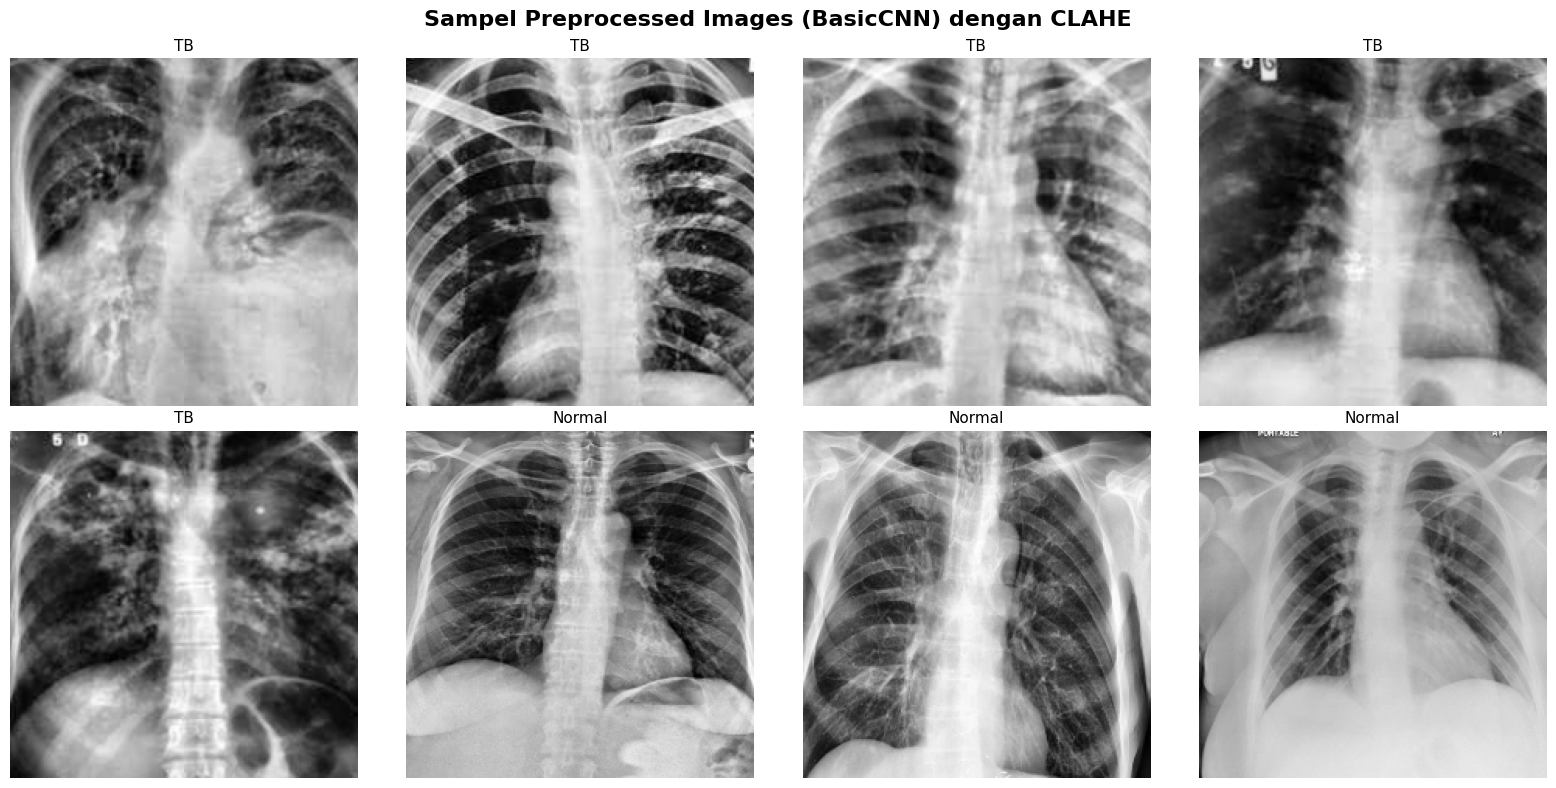

Preprocessed samples saved.


In [24]:
# ============================================================
# 3.4 Visualisasi Sampel Preprocessed Images
# ============================================================

# Ambil satu batch untuk visualisasi
for images, labels in ds_train.take(1):
    sample_images = images[:8]
    sample_labels = labels[:8]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Sampel Preprocessed Images (BasicCNN) dengan CLAHE', fontsize=16, fontweight='bold')

label_names = {0: 'Normal', 1: 'TB'}

for i, ax in enumerate(axes.flat):
    if i < len(sample_images):
        # Squeeze channel dimension untuk visualisasi grayscale (H, W)
        img = np.squeeze(sample_images[i].numpy())
        # Clip values ke [0,1] untuk tampilan
        img = np.clip(img, 0.0, 1.0)
        ax.imshow(img, cmap='gray')
        lbl_idx = np.argmax(sample_labels[i]) if sample_labels[i].shape else int(sample_labels[i])
        ax.set_title(f'{label_names[lbl_idx]}', fontsize=11)
    ax.axis('off')

plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / 'preprocessed_samples_basiccnn.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Preprocessed samples saved.')


In [25]:
# ============================================================
# 3.5 Checkpoint: Verifikasi Pipeline
# ============================================================

print('=' * 60)
print('CHECKPOINT: Pipeline Verification')
print('=' * 60)

for name, ds in [('Train', ds_train), ('Val', ds_val), ('Test', ds_test)]:
    for images, labels in ds.take(1):
        print(f'\n{name}:')
        print(f'  Image batch shape : {images.shape}')
        print(f'  Label batch shape : {labels.shape}')
        print(f'  Image dtype       : {images.dtype}')
        print(f'  Label dtype       : {labels.dtype}')
        print(f'  Pixel range       : [{images.numpy().min():.3f}, {images.numpy().max():.3f}]')
        print(f'  Labels sample     : {np.argmax(labels.numpy()[:8], axis=1)}')
        break

print('\n✓ Pipeline verification complete.')


CHECKPOINT: Pipeline Verification

Train:
  Image batch shape : (32, 224, 224, 1)
  Label batch shape : (32, 2)
  Image dtype       : <dtype: 'float32'>
  Label dtype       : <dtype: 'float32'>
  Pixel range       : [0.002, 1.000]
  Labels sample     : [0 0 0 0 0 1 1 1]

Val:
  Image batch shape : (32, 224, 224, 1)
  Label batch shape : (32, 2)
  Image dtype       : <dtype: 'float32'>
  Label dtype       : <dtype: 'float32'>
  Pixel range       : [0.004, 1.000]
  Labels sample     : [0 0 0 1 0 0 1 0]

Test:
  Image batch shape : (32, 224, 224, 1)
  Label batch shape : (32, 2)
  Image dtype       : <dtype: 'float32'>
  Label dtype       : <dtype: 'float32'>
  Pixel range       : [0.004, 1.000]
  Labels sample     : [0 0 0 1 0 0 0 1]

✓ Pipeline verification complete.


---
## 4. Model Architecture (Basic CNN)

Arsitektur CNN yang diimplementasikan:

| Layer | Output Shape | Detail |
|-------|-------------|--------|
| Input | 224×224×1 | Grey Scale Image |
| Block 1 | 112×112×32 | Conv(32, 3×3) → BN → ReLU → MaxPool(2,2) |
| Block 2 | 56×56×64 | Conv(64, 3×3) → BN → ReLU → MaxPool(2,2) |
| Block 3 | 28×28×128 | Conv(128, 3×3) → BN → ReLU → MaxPool(2,2) |
| Block 4 | 14×14×256 | Conv(256, 3×3) → BN → ReLU → MaxPool(2,2) |
| AdaptiveAvgPool | 2×2×256 | AvgPool(7,7) → 1024-dim |
| Flatten | 1024 | - |
| Dense 1 | 512 | ReLU + Dropout(0.5) |
| Dense 2 | 256 | ReLU + Dropout(0.4) |
| Output | 2 | Softmax |

In [26]:
# ============================================================
# 4.1 Build BasicCNN Model (1 Channel, Softmax) - FIXED VERSION
# ============================================================

def build_basic_cnn(input_shape=(224, 224, 1), num_classes=2):
    inputs = layers.Input(shape=input_shape, name='input_image')
    
    # Block 1: Conv(32) -> BN -> ReLU -> MaxPool(2,2) -> 112x112
    x = layers.Conv2D(32, (3, 3), padding='same', kernel_initializer='he_normal', name='block1_conv')(inputs)
    x = layers.BatchNormalization(name='block1_bn')(x)
    x = layers.Activation('relu', name='block1_relu')(x)
    x = layers.MaxPooling2D(pool_size=(2, 2), name='block1_pool')(x)
    
    # Block 2: Conv(64) -> BN -> ReLU -> MaxPool(2,2) -> 56x56
    x = layers.Conv2D(64, (3, 3), padding='same', kernel_initializer='he_normal', name='block2_conv')(x)
    x = layers.BatchNormalization(name='block2_bn')(x)
    x = layers.Activation('relu', name='block2_relu')(x)
    x = layers.MaxPooling2D(pool_size=(2, 2), name='block2_pool')(x)
    # FIX #6: Dropout dihapus dari conv blocks — terlalu agresif untuk model from-scratch
    
    # Block 3: Conv(128) -> BN -> ReLU -> MaxPool(2,2) -> 28x28
    x = layers.Conv2D(128, (3, 3), padding='same', kernel_initializer='he_normal', name='block3_conv')(x)
    x = layers.BatchNormalization(name='block3_bn')(x)
    x = layers.Activation('relu', name='block3_relu')(x)
    x = layers.MaxPooling2D(pool_size=(2, 2), name='block3_pool')(x)
    
    # Block 4: Conv(256) -> BN -> ReLU -> MaxPool(2,2) -> 14x14
    x = layers.Conv2D(256, (3, 3), padding='same', kernel_initializer='he_normal', name='block4_conv')(x)
    x = layers.BatchNormalization(name='block4_bn')(x)
    x = layers.Activation('relu', name='block4_relu')(x)
    x = layers.MaxPooling2D(pool_size=(2, 2), name='block4_pool')(x)
    
    # AdaptiveAvgPool(7,7) -> 14/7 = 2x2. Menggunakan AveragePooling2D.
    x = layers.AveragePooling2D(pool_size=(7, 7), strides=(7, 7), name='adaptive_avg_pool')(x)
    
    # Flatten -> 2*2*256 = 1024-dim
    x = layers.Flatten(name='flatten')(x)
    
    # FIX #4: Restore arsitektur Dense(512) -> Dense(256) -> Dense(2) sesuai deskripsi
    x = layers.Dense(512, kernel_initializer='he_normal', name='fc1')(x)
    x = layers.Activation('relu', name='fc1_relu')(x)
    x = layers.Dropout(0.5, name='fc1_dropout')(x)
    
    x = layers.Dense(256, kernel_initializer='he_normal', name='fc2')(x)
    x = layers.Activation('relu', name='fc2_relu')(x)
    x = layers.Dropout(0.4, name='fc2_dropout')(x)
    
    # Output 2 nodes (Softmax)
    outputs = layers.Dense(num_classes, activation='softmax', name='output')(x)
    
    model = Model(inputs=inputs, outputs=outputs, name='BasicCNN_1Channel_v2')
    return model

model = build_basic_cnn()
model.summary()


Model: "BasicCNN_1Channel_v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv (Conv2D)            │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn (BatchNormalization)  │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_relu (Activation)        │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv (Conv2D)            │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn (BatchNormalization)  │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_relu (Activation)        │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv (Conv2D)            │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn (BatchNormalization)  │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_relu (Activation)        │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv (Conv2D)            │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_bn (BatchNormalization)  │ (None, 28, 28, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_relu (Activation)        │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ adaptive_avg_pool               │ (None, 2, 2, 256)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1_relu (Activation)           │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1_dropout (Dropout)           │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2_relu (Activation)           │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,046,402 (3.99 MB)

 Trainable params: 1,045,442 (3.99 MB)

 Non-trainable params: 960 (3.75 KB)

In [27]:
# ============================================================
# 4.2 Model Summary
# ============================================================

model.summary()

# Hitung parameter
total_params = model.count_params()
trainable_params = sum(tf.keras.backend.count_params(w) for w in model.trainable_weights)
non_trainable_params = total_params - trainable_params

print(f'\n{"="*50}')
print(f'Total parameters     : {total_params:>12,}')
print(f'Trainable parameters : {trainable_params:>12,}')
print(f'Non-trainable params : {non_trainable_params:>12,}')
print(f'{"="*50}')
print(f'\nSemua parameter trainable (tidak ada frozen base).')


Model: "BasicCNN_1Channel_v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv (Conv2D)            │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn (BatchNormalization)  │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_relu (Activation)        │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv (Conv2D)            │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn (BatchNormalization)  │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_relu (Activation)        │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv (Conv2D)            │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn (BatchNormalization)  │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_relu (Activation)        │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv (Conv2D)            │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_bn (BatchNormalization)  │ (None, 28, 28, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_relu (Activation)        │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ adaptive_avg_pool               │ (None, 2, 2, 256)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1_relu (Activation)           │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1_dropout (Dropout)           │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2_relu (Activation)           │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,046,402 (3.99 MB)

 Trainable params: 1,045,442 (3.99 MB)

 Non-trainable params: 960 (3.75 KB)


Total parameters     :    1,046,402
Trainable parameters :    1,045,442
Non-trainable params :          960

Semua parameter trainable (tidak ada frozen base).


---
## 5. Training

In [28]:
# ============================================================
# 5.1 Compute Class Weights
# ============================================================

class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.array([0, 1]),
    y=df_train['label_encoded'].values
)

class_weight_dict = {0: class_weights_array[0], 1: class_weights_array[1]}
print('Class weights (balanced):')
print(f'  Normal (0): {class_weight_dict[0]:.4f}')
print(f'  TB     (1): {class_weight_dict[1]:.4f}')


Class weights (balanced):
  Normal (0): 0.8978
  TB     (1): 1.1284


In [29]:
# ============================================================
# 5.2 Compile & Train Model
# ============================================================

# Compile
model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss='categorical_crossentropy',  # Menggunakan categorical karena label sudah one-hot
    metrics=[
        'accuracy',
        AUC(name='auc'),
        Precision(name='precision'),
        Recall(name='recall'),
    ]
)

# Callbacks
callbacks = [
    EarlyStopping(
        monitor='val_auc',
        patience=10,
        mode='max',
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_auc',
        factor=0.5,
        patience=5,
        mode='max',
        min_lr=1e-7,
        verbose=1
    ),
    ModelCheckpoint(
        filepath=str(OUTPUT_DIR / 'best_BasicCNN_v2.keras'),
        monitor='val_auc',
        mode='max',
        save_best_only=True,
        verbose=1
    ),
]

print('Model compiled.')
print(f'  Optimizer    : Adam (lr={LEARNING_RATE})')
print(f'  Loss         : CategoricalCrossentropy')
print(f'  Metrics      : accuracy, AUC, Precision, Recall')
print(f'  EarlyStopping: patience=10, monitor=val_auc')
print(f'  ReduceLR     : patience=5, factor=0.5')
print(f'\nStarting training for up to {EPOCHS} epochs...')


Model compiled.
  Optimizer    : Adam (lr=0.0005)
  Loss         : CategoricalCrossentropy
  Metrics      : accuracy, AUC, Precision, Recall
  EarlyStopping: patience=10, monitor=val_auc
  ReduceLR     : patience=5, factor=0.5

Starting training for up to 50 epochs...


In [30]:
# ============================================================
# 5.3 Training Loop
# ============================================================

history = model.fit(
    ds_train,
    validation_data=ds_val,
    epochs=EPOCHS,
    class_weight=class_weight_dict,
    callbacks=callbacks,
    verbose=1
)

print(f'\n✓ Training selesai: {len(history.history["loss"])} epochs')
print(f'  Best val_auc: {max(history.history["val_auc"]):.4f}')


Epoch 1/50
158/158 ━━━━━━━━━━━━━━━━━━━━ 0s 597ms/step - accuracy: 0.7484 - auc: 0.8099 - loss: 0.6104 - precision: 0.7484 - recall: 0.7484
Epoch 1: val_auc improved from None to 0.44362, saving model to c:\Users\Monk\Downloads\Deteksi Tuberkulosis (TB)\outputs\best_BasicCNN_v2.keras

Epoch 1: finished saving model to c:\Users\Monk\Downloads\Deteksi Tuberkulosis (TB)\outputs\best_BasicCNN_v2.keras
158/158 ━━━━━━━━━━━━━━━━━━━━ 101s 626ms/step - accuracy: 0.8618 - auc: 0.9359 - loss: 0.3433 - precision: 0.8618 - recall: 0.8618 - val_accuracy: 0.4436 - val_auc: 0.4436 - val_loss: 7.6372 - val_precision: 0.4436 - val_recall: 0.4436 - learning_rate: 5.0000e-04
Epoch 2/50
158/158 ━━━━━━━━━━━━━━━━━━━━ 0s 599ms/step - accuracy: 0.9544 - auc: 0.9874 - loss: 0.1362 - precision: 0.9544 - recall: 0.9544
Epoch 2: val_auc did not improve from 0.44362
158/158 ━━━━━━━━━━━━━━━━━━━━ 99s 626ms/step - accuracy: 0.9564 - auc: 0.9884 - loss: 0.1304 - precision: 0.9564 - recall: 0.9564 - val_accuracy: 0.4436 

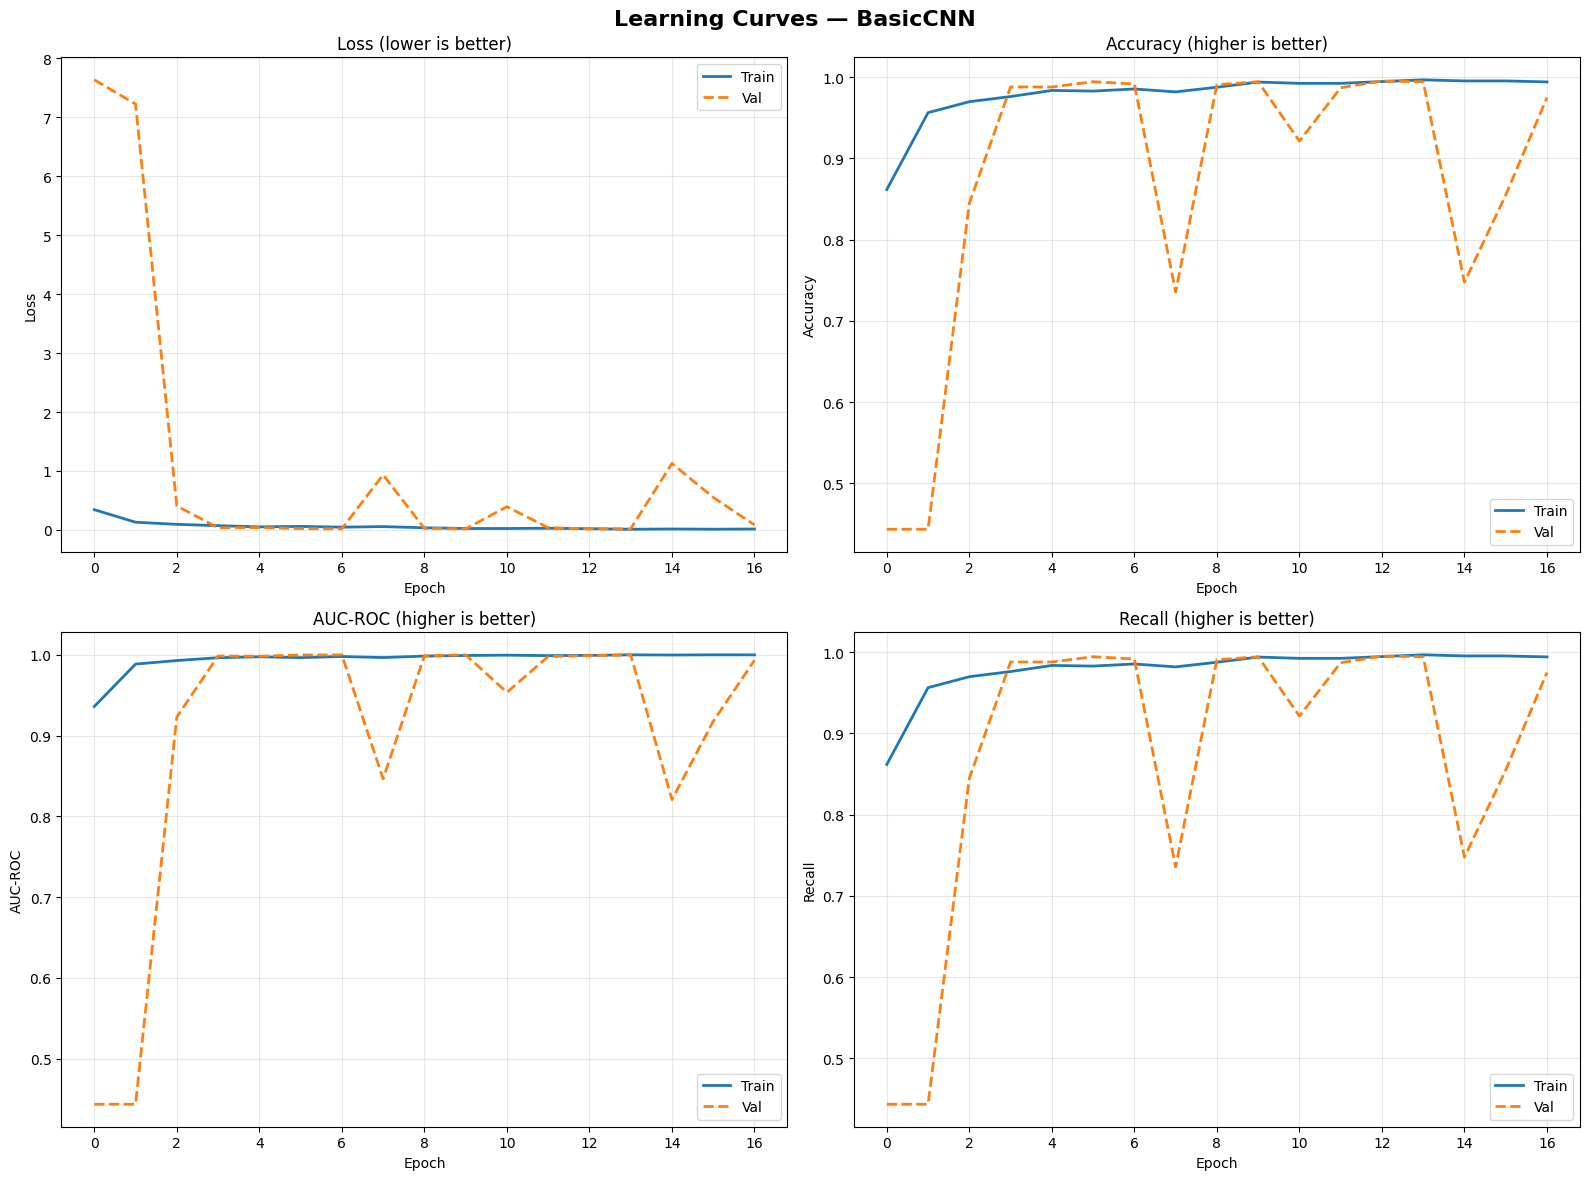

Learning curves saved.


In [31]:
# ============================================================
# 5.4 Plot Learning Curves
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Learning Curves — BasicCNN', fontsize=16, fontweight='bold')

metrics_to_plot = [
    ('loss', 'val_loss', 'Loss', 'lower is better'),
    ('accuracy', 'val_accuracy', 'Accuracy', 'higher is better'),
    ('auc', 'val_auc', 'AUC-ROC', 'higher is better'),
    ('recall', 'val_recall', 'Recall', 'higher is better'),
]

for ax, (train_key, val_key, title, note) in zip(axes.flat, metrics_to_plot):
    if train_key in history.history:
        ax.plot(history.history[train_key], label=f'Train', linewidth=2)
        ax.plot(history.history[val_key], label=f'Val', linewidth=2, linestyle='--')
        ax.set_title(f'{title} ({note})', fontsize=12)
        ax.set_xlabel('Epoch')
        ax.set_ylabel(title)
        ax.legend()
        ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / 'learning_curves_basiccnn.png'), dpi=150, bbox_inches='tight')
plt.show()

print('Learning curves saved.')


---
## 6. Evaluation

In [32]:
# ============================================================
# 6.1 Load Best Model & Evaluasi pada Test Set
# ============================================================

# Load best model
best_model_path = OUTPUT_DIR / 'best_BasicCNN_v2.keras'
if best_model_path.exists():
    model = keras.models.load_model(str(best_model_path))
    print(f'✓ Best model loaded from: {best_model_path}')
else:
    print('Using current model (no checkpoint found).')

# Prediksi pada test set
y_prob_all = model.predict(ds_test, verbose=1)  # Shape: (N, 2)
y_prob = y_prob_all[:, 1]  # Probabilitas dari node Softmax kelas TB (Indeks 1)
y_pred = (y_prob >= 0.5).astype(int)
y_true = df_test['label_encoded'].values

# Metrics
acc = accuracy_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)
fpr, tpr, thresholds_roc = roc_curve(y_true, y_prob)
roc_auc_val = auc(fpr, tpr)

precision_curve, recall_curve, thresholds_pr = precision_recall_curve(y_true, y_prob)
pr_auc_val = auc(recall_curve, precision_curve)

cr = classification_report(y_true, y_pred, target_names=['Normal', 'TB'], output_dict=True)

print(f'\n{"="*60}')
print(f'TEST SET EVALUATION — BasicCNN')
print(f'{"="*60}')
print(f'  Accuracy    : {acc:.4f}')
print(f'  AUC-ROC     : {roc_auc_val:.4f}')
print(f'  AUC-PR      : {pr_auc_val:.4f}')
print(f'  F1-Score    : {f1:.4f}')
print(f'  TB Recall   : {cr["TB"]["recall"]:.4f}')
print(f'  TB Precision: {cr["TB"]["precision"]:.4f}')
print(f'{"="*60}')

# Full classification report
print(f'\n{classification_report(y_true, y_pred, target_names=["Normal", "TB"])}')


✓ Best model loaded from: c:\Users\Monk\Downloads\Deteksi Tuberkulosis (TB)\outputs\best_BasicCNN_v2.keras
34/34 ━━━━━━━━━━━━━━━━━━━━ 4s 122ms/step

TEST SET EVALUATION — BasicCNN
  Accuracy    : 0.9945
  AUC-ROC     : 0.9990
  AUC-PR      : 0.9991
  F1-Score    : 0.9937
  TB Recall   : 0.9875
  TB Precision: 1.0000

              precision    recall  f1-score   support

      Normal       0.99      1.00      1.00       603
          TB       1.00      0.99      0.99       479

    accuracy                           0.99      1082
   macro avg       1.00      0.99      0.99      1082
weighted avg       0.99      0.99      0.99      1082



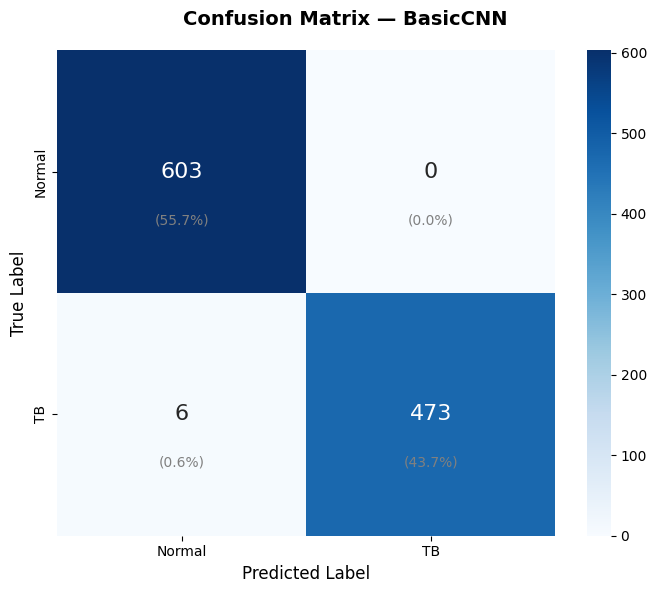

TN=603 | FP=0
FN=6 | TP=473


In [33]:
# ============================================================
# 6.2 Confusion Matrix
# ============================================================

cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(1, 1, figsize=(7, 6))
fig.suptitle('Confusion Matrix — BasicCNN', fontsize=14, fontweight='bold')

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal', 'TB'],
            yticklabels=['Normal', 'TB'],
            ax=ax, annot_kws={'size': 16})
ax.set_ylabel('True Label', fontsize=12)
ax.set_xlabel('Predicted Label', fontsize=12)

# Tambahkan persentase
total = cm.sum()
for i in range(2):
    for j in range(2):
        pct = cm[i, j] / total * 100
        ax.text(j + 0.5, i + 0.7, f'({pct:.1f}%)',
                ha='center', va='center', fontsize=10, color='gray')

plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / 'confusion_matrix_basiccnn.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f'TN={cm[0,0]} | FP={cm[0,1]}')
print(f'FN={cm[1,0]} | TP={cm[1,1]}')


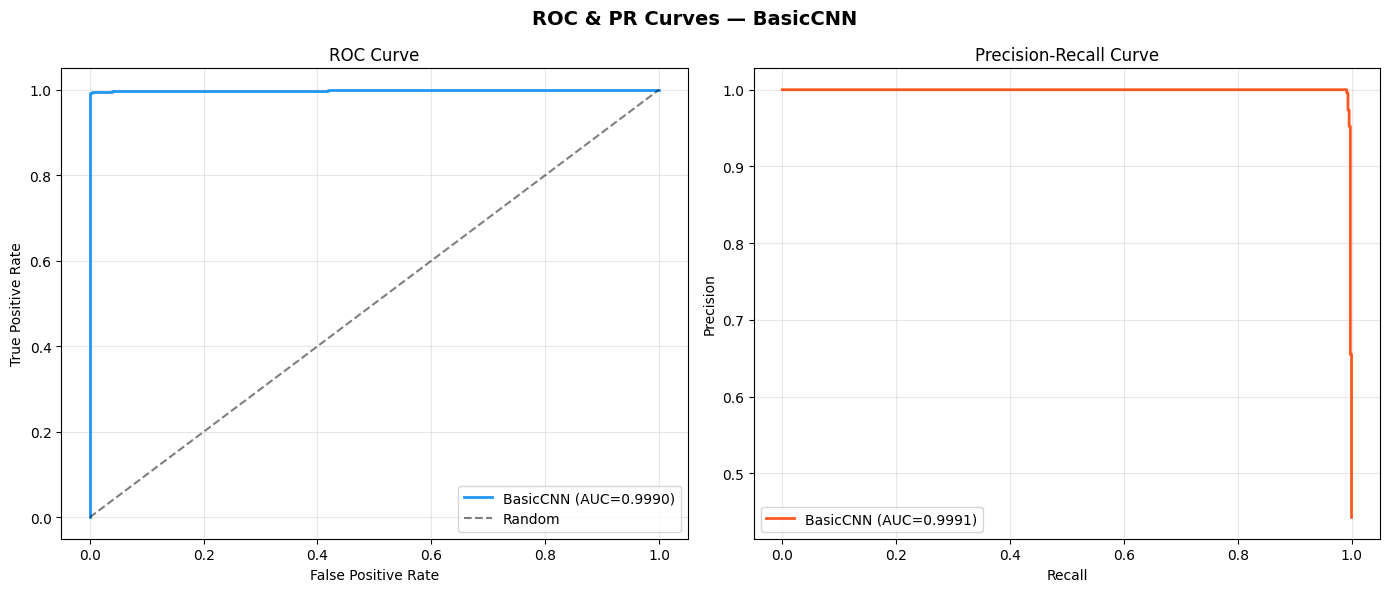

In [34]:
# ============================================================
# 6.3 ROC Curve & Precision-Recall Curve
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('ROC & PR Curves — BasicCNN', fontsize=14, fontweight='bold')

# ROC Curve
axes[0].plot(fpr, tpr, color='#2196F3', linewidth=2,
             label=f'BasicCNN (AUC={roc_auc_val:.4f})')
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve')
axes[0].legend(loc='lower right')
axes[0].grid(True, alpha=0.3)

# PR Curve
axes[1].plot(recall_curve, precision_curve, color='#FF5722', linewidth=2,
             label=f'BasicCNN (AUC={pr_auc_val:.4f})')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curve')
axes[1].legend(loc='lower left')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / 'roc_pr_curves_basiccnn.png'), dpi=150, bbox_inches='tight')
plt.show()


Threshold Optimization (target TB recall ≥ 0.95)
  Optimal threshold : 0.01
  Accuracy (opt)    : 0.9168
  F1 (opt)          : 0.9140
  TB Recall (opt)   : 0.9979
  TB Precision (opt): 0.8430


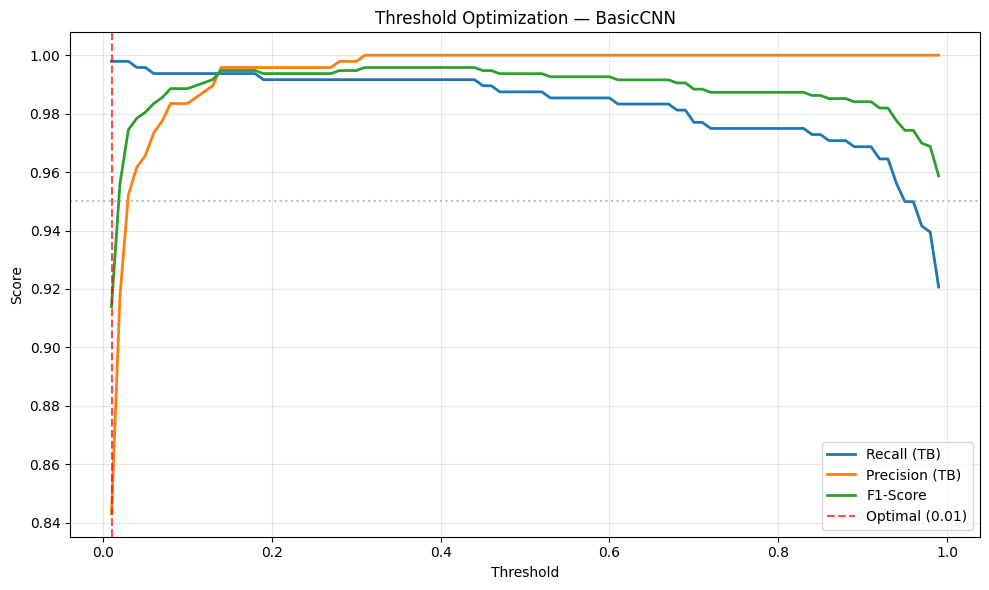

In [35]:
# ============================================================
# 6.4 Threshold Optimization (Recall TB ≥ 0.95)
# ============================================================

# Cari threshold optimal untuk recall TB ≥ 0.95
target_recall = 0.95
optimal_threshold = 0.5  # default

for thresh in np.arange(0.01, 1.0, 0.01):
    y_pred_thresh = (y_prob >= thresh).astype(int)
    recall_tb = np.sum((y_true == 1) & (y_pred_thresh == 1)) / max(np.sum(y_true == 1), 1)
    if recall_tb >= target_recall:
        optimal_threshold = thresh
        break

# Evaluasi dengan threshold optimal
y_pred_opt = (y_prob >= optimal_threshold).astype(int)
acc_opt = accuracy_score(y_true, y_pred_opt)
f1_opt = f1_score(y_true, y_pred_opt)
cr_opt = classification_report(y_true, y_pred_opt, target_names=['Normal', 'TB'], output_dict=True)

print(f'Threshold Optimization (target TB recall ≥ {target_recall})')
print(f'{"="*50}')
print(f'  Optimal threshold : {optimal_threshold:.2f}')
print(f'  Accuracy (opt)    : {acc_opt:.4f}')
print(f'  F1 (opt)          : {f1_opt:.4f}')
print(f'  TB Recall (opt)   : {cr_opt["TB"]["recall"]:.4f}')
print(f'  TB Precision (opt): {cr_opt["TB"]["precision"]:.4f}')

# Visualisasi threshold vs metrics
thresholds_range = np.arange(0.01, 1.0, 0.01)
recalls = []
precisions = []
f1s = []

for t in thresholds_range:
    yp = (y_prob >= t).astype(int)
    r = np.sum((y_true == 1) & (yp == 1)) / max(np.sum(y_true == 1), 1)
    p = np.sum((y_true == 1) & (yp == 1)) / max(np.sum(yp == 1), 1)
    recalls.append(r)
    precisions.append(p)
    f1s.append(2 * p * r / max(p + r, 1e-8))

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(thresholds_range, recalls, label='Recall (TB)', linewidth=2)
ax.plot(thresholds_range, precisions, label='Precision (TB)', linewidth=2)
ax.plot(thresholds_range, f1s, label='F1-Score', linewidth=2)
ax.axvline(x=optimal_threshold, color='red', linestyle='--', alpha=0.7,
           label=f'Optimal ({optimal_threshold:.2f})')
ax.axhline(y=target_recall, color='gray', linestyle=':', alpha=0.5)
ax.set_xlabel('Threshold')
ax.set_ylabel('Score')
ax.set_title('Threshold Optimization — BasicCNN')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / 'threshold_optimization_basiccnn.png'), dpi=150, bbox_inches='tight')
plt.show()


---
## 7. Error Analysis & Grad-CAM

In [36]:
# ============================================================
# 7.1 Breakdown Metrik per Sumber Dataset
# ============================================================

# Tambahkan prediksi ke dataframe test
df_test_eval = df_test.copy()
df_test_eval['y_prob'] = y_prob
df_test_eval['y_pred'] = y_pred
df_test_eval['correct'] = (df_test_eval['y_pred'] == df_test_eval['label_encoded']).astype(int)

print('Metrik per sumber dataset:')
print('=' * 60)

for source in df_test_eval['source'].unique():
    mask = df_test_eval['source'] == source
    df_src = df_test_eval[mask]
    
    yt = df_src['label_encoded'].values
    yp_src = df_src['y_pred'].values
    yprob = df_src['y_prob'].values
    
    acc_src = accuracy_score(yt, yp_src)
    
    if len(np.unique(yt)) > 1:
        fpr_src, tpr_src, _ = roc_curve(yt, yprob)
        auc_src = auc(fpr_src, tpr_src)
        f1_src = f1_score(yt, yp_src)
    else:
        auc_src = float('nan')
        f1_src = float('nan')
    
    print(f'\n  {source.capitalize()} (n={len(df_src)}):')
    print(f'    Accuracy: {acc_src:.4f} | AUC: {auc_src:.4f} | F1: {f1_src:.4f}')

# Gap analysis
print('\n' + '=' * 60)
sources = df_test_eval['source'].unique()
if len(sources) >= 2:
    accs = {}
    for s in sources:
        accs[s] = df_test_eval.loc[df_test_eval['source'] == s, 'correct'].mean()
    gap = abs(max(accs.values()) - min(accs.values()))
    print(f'Gap akurasi antar sumber: {gap:.4f}')
    if gap > 0.10:
        print('⚠ Gap signifikan (>10%)!')
    elif gap > 0.05:
        print('⚠ Gap moderat (5-10%).')
    else:
        print('✓ Gap rendah (<5%). Generalisasi baik.')


Metrik per sumber dataset:

  Mendeley (n=451):
    Accuracy: 0.9978 | AUC: 0.9998 | F1: 0.9987

  Kaggle (n=631):
    Accuracy: 0.9921 | AUC: 0.9959 | F1: 0.9756

Gap akurasi antar sumber: 0.0057
✓ Gap rendah (<5%). Generalisasi baik.


False Positives (Normal→TB): 0
False Negatives (TB→Normal): 6
  Tidak ada False Positives (Normal diprediksi TB).


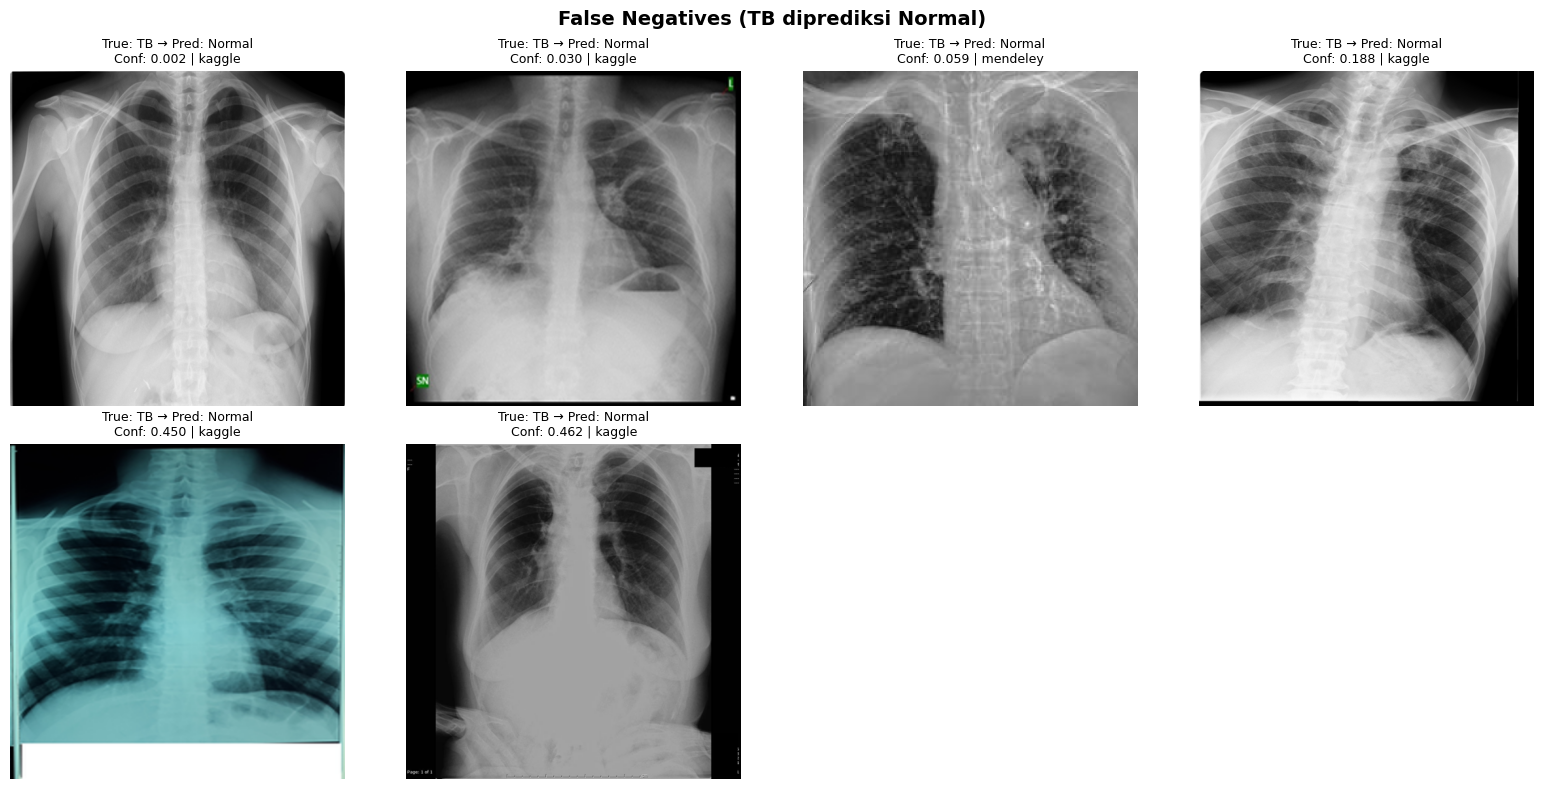

In [37]:
# ============================================================
# 7.2 Visualisasi Misclassified Samples
# ============================================================

# False Positives (Normal → predicted TB)
fp_mask = (df_test_eval['label_encoded'] == 0) & (df_test_eval['y_pred'] == 1)
# False Negatives (TB → predicted Normal)
fn_mask = (df_test_eval['label_encoded'] == 1) & (df_test_eval['y_pred'] == 0)

print(f'False Positives (Normal→TB): {fp_mask.sum()}')
print(f'False Negatives (TB→Normal): {fn_mask.sum()}')

def plot_misclassified(df_subset, title, n_show=8):
    """Plot grid of misclassified images."""
    n = min(n_show, len(df_subset))
    if n == 0:
        print(f'  Tidak ada {title}.')
        return
    
    samples = df_subset.head(n)
    cols = min(4, n)
    rows = (n + cols - 1) // cols
    
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
    fig.suptitle(title, fontsize=14, fontweight='bold')
    
    if rows == 1 and cols == 1:
        axes = np.array([axes])
    axes = np.array(axes).flatten()
    
    for i, (_, row) in enumerate(samples.iterrows()):
        if i >= len(axes):
            break
        ax = axes[i]
        img = cv2.imread(row['filepath'])
        if img is not None:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            ax.imshow(img)
        true_label = 'TB' if row['label_encoded'] == 1 else 'Normal'
        pred_label = 'TB' if row['y_pred'] == 1 else 'Normal'
        ax.set_title(f'True: {true_label} → Pred: {pred_label}\n'
                    f'Conf: {row["y_prob"]:.3f} | {row["source"]}',
                    fontsize=9)
        ax.axis('off')
    
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')
    
    plt.tight_layout()
    plt.show()

# Sort by confidence (most confident mistakes first)
fp_sorted = df_test_eval[fp_mask].sort_values('y_prob', ascending=False)
fn_sorted = df_test_eval[fn_mask].sort_values('y_prob', ascending=True)

plot_misclassified(fp_sorted, 'False Positives (Normal diprediksi TB)')
plot_misclassified(fn_sorted, 'False Negatives (TB diprediksi Normal)')


In [43]:
# ============================================================
# 7.3 Grad-CAM Implementation
# ============================================================

def get_gradcam_heatmap(model, img_array, last_conv_layer_name=None):
    """
    Generate Grad-CAM heatmap for BasicCNN.
    
    Args:
        model: Trained BasicCNN model
        img_array: Preprocessed image array (1, H, W, 1), normalized [0,1], GRAYSCALE
        last_conv_layer_name: Name of last conv layer (auto-detected if None)
    """
    if last_conv_layer_name is None:
        for layer in reversed(model.layers):
            if isinstance(layer, tf.keras.layers.Conv2D):
                last_conv_layer_name = layer.name
                break
    
    if last_conv_layer_name is None:
        print('Warning: Could not find last conv layer!')
        return np.zeros(IMG_SIZE)
    
    grad_model = Model(
        inputs=model.input,
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )
    
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        loss = predictions[:, 1]
    
    grads = tape.gradient(loss, conv_outputs)
    if grads is None:
        return np.zeros(IMG_SIZE)
    
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()


def preprocess_for_gradcam(filepath):
    """Load gambar sesuai pipeline model: grayscale, central crop, resize, normalize."""
    img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
    h, w = img.shape[:2]
    crop_h, crop_w = int(h * 0.85), int(w * 0.85)
    sh, sw = (h - crop_h) // 2, (w - crop_w) // 2
    img = img[sh:sh+crop_h, sw:sw+crop_w]
    img = cv2.resize(img, IMG_SIZE)
    img = img.astype(np.float32) / 255.0
    return np.expand_dims(np.expand_dims(img, -1), 0)  # → (1, 224, 224, 1)


def overlay_gradcam(img_path, heatmap, alpha=0.4):
    """Overlay Grad-CAM heatmap on original image."""
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, IMG_SIZE)
    heatmap_resized = cv2.resize(heatmap, IMG_SIZE)
    heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)
    superimposed = np.uint8(heatmap_colored * alpha + img * (1 - alpha))
    return img, superimposed

print('Grad-CAM functions defined for BasicCNN (1-channel).')


Grad-CAM functions defined for BasicCNN (1-channel).


Grad-CAM functions defined for BasicCNN (1-channel).


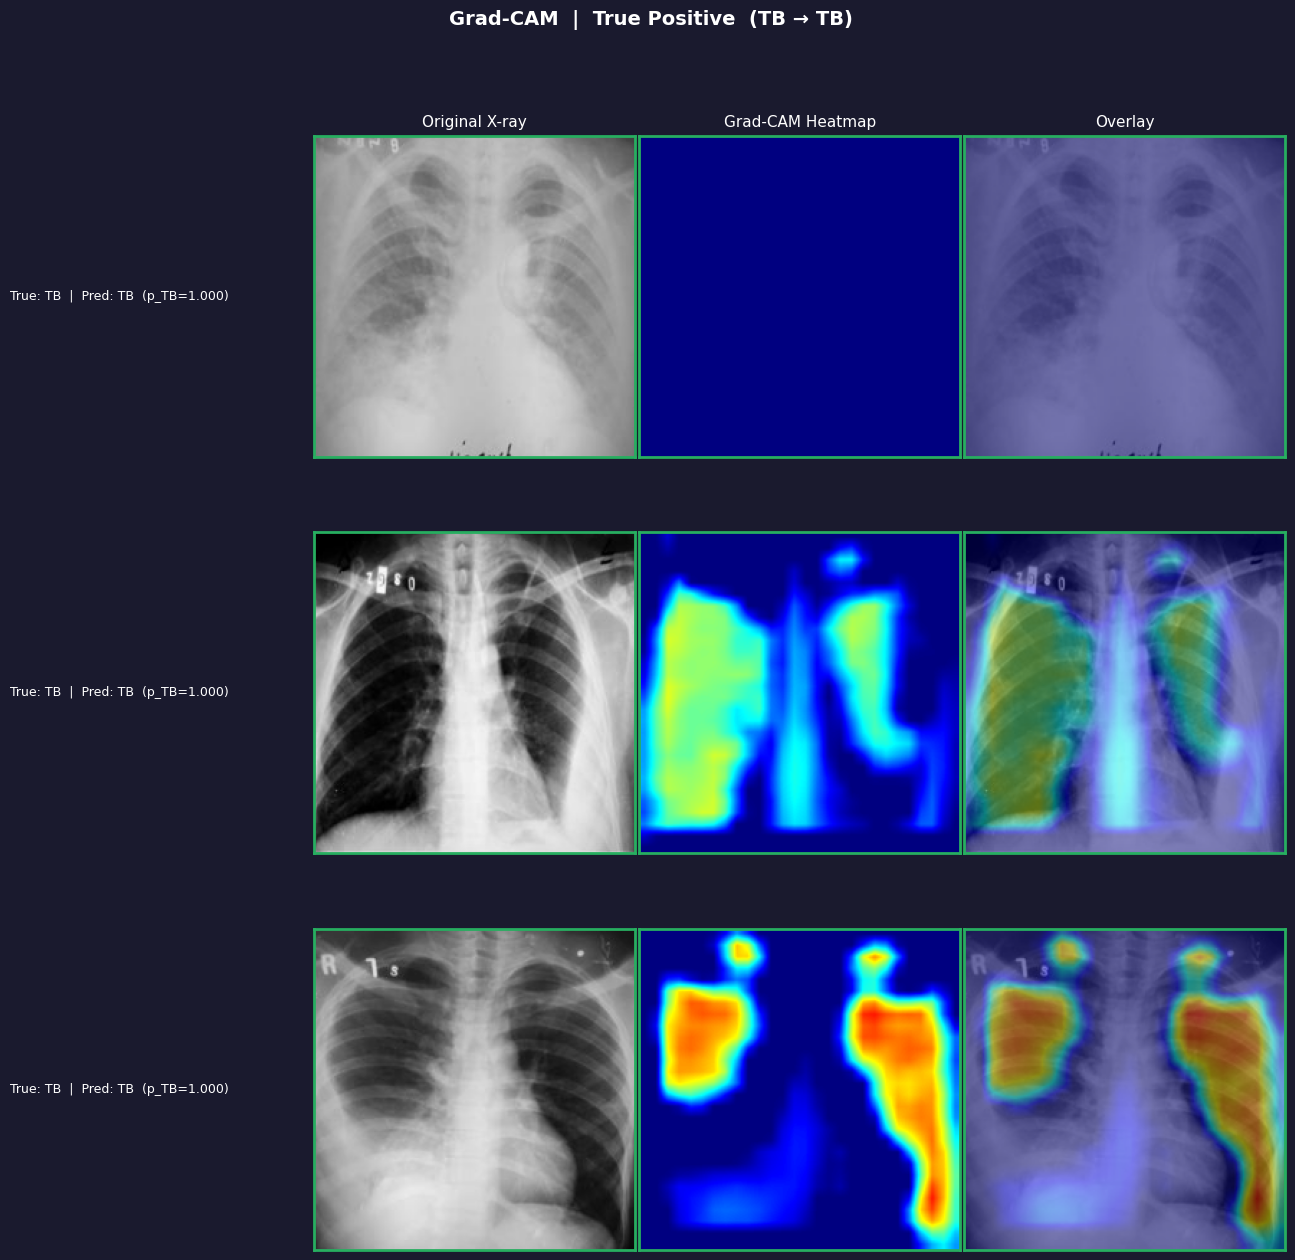

Saved: gradcam_true_positive.png


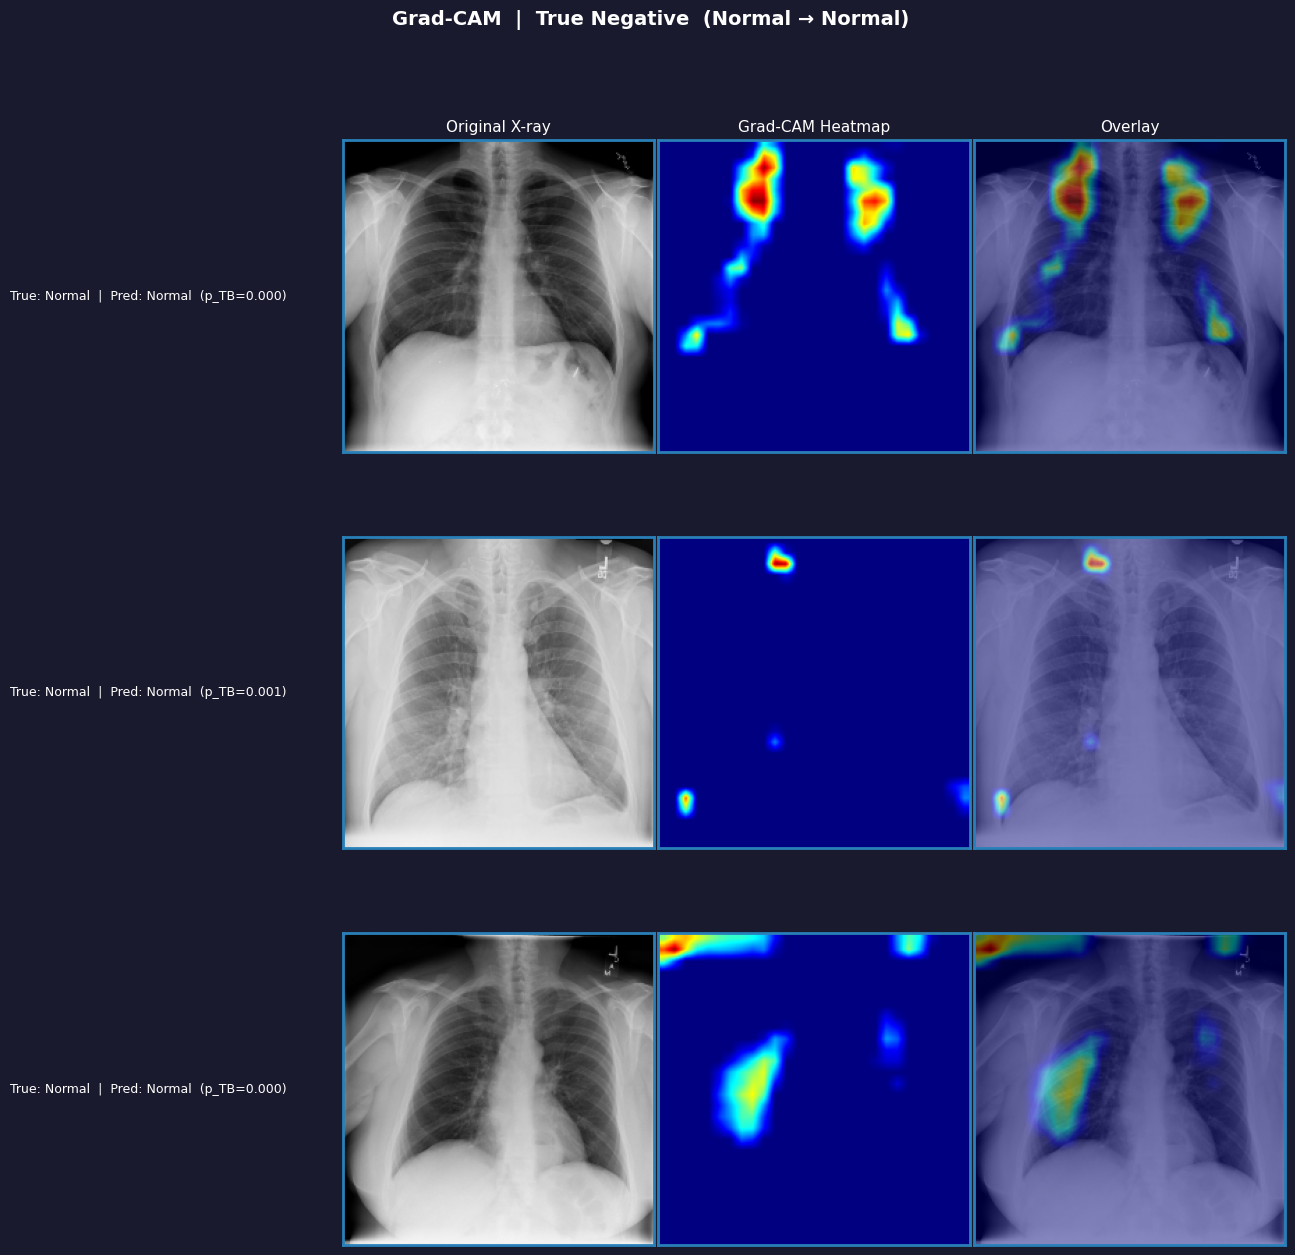

Saved: gradcam_true_negative.png
Tidak ada sampel untuk: False Positive (Normal → TB)


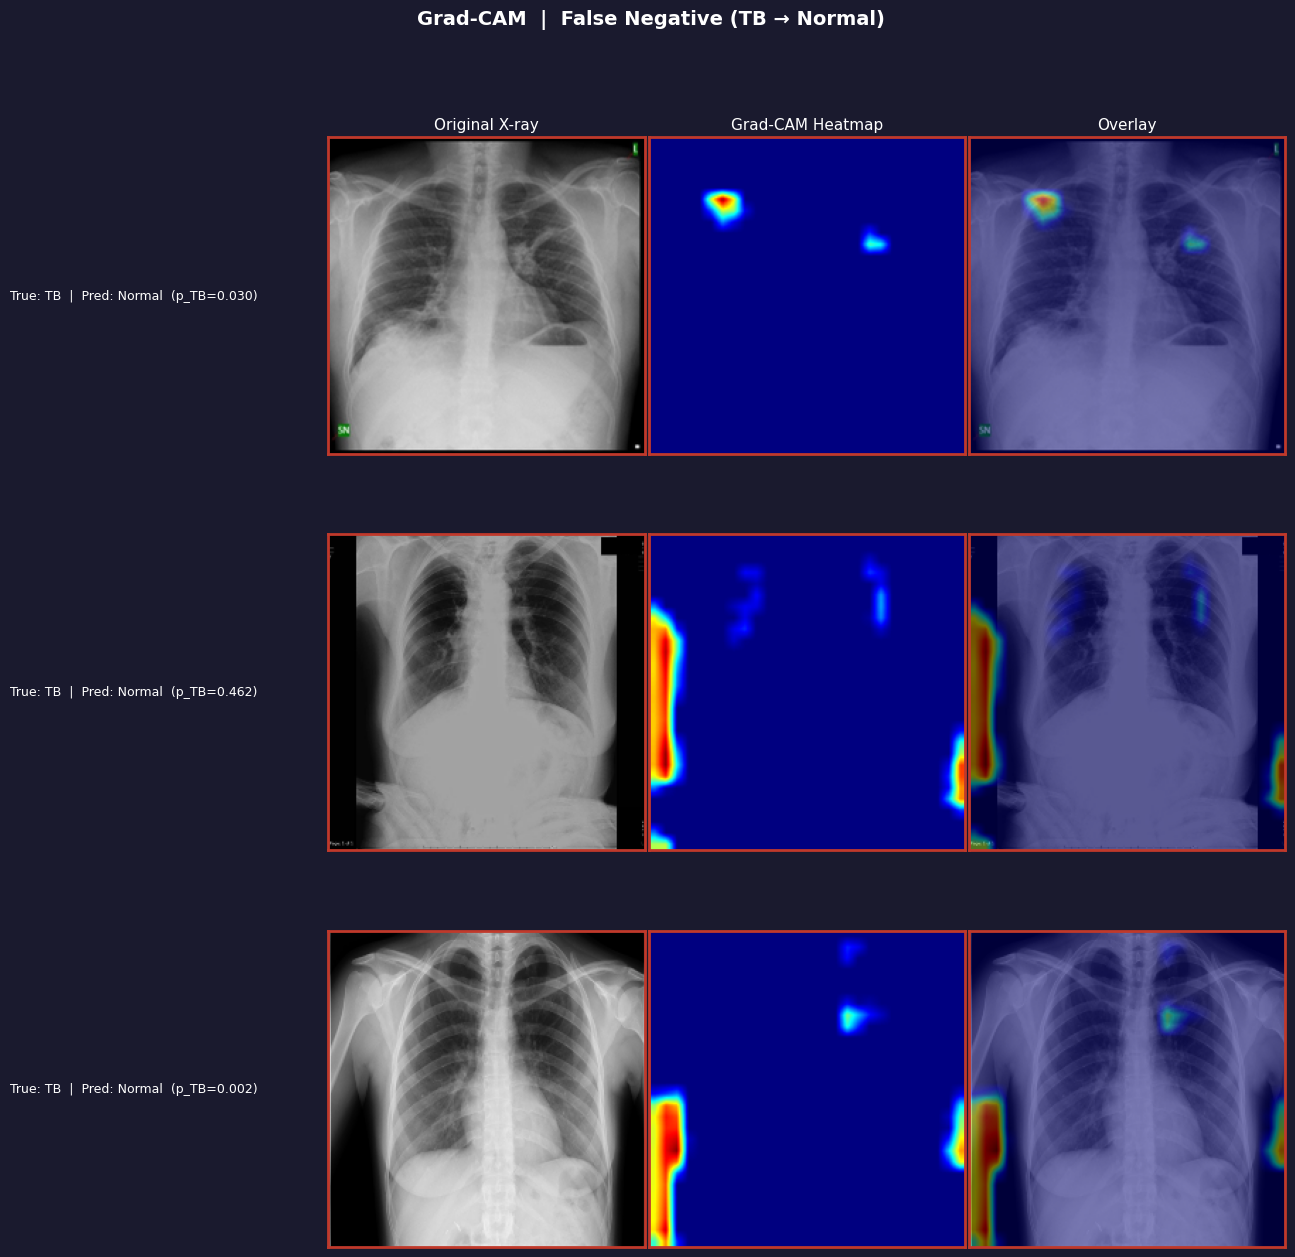

Saved: gradcam_false_negative.png

Selesai — semua Grad-CAM visualisasi ditampilkan.


In [45]:
# ============================================================
# 7.3 Grad-CAM Implementation
# ============================================================

def get_gradcam_heatmap(model, img_array, last_conv_layer_name=None):
    """
    Generate Grad-CAM heatmap for BasicCNN.
    
    Args:
        model: Trained BasicCNN model
        img_array: Preprocessed image array (1, H, W, 1), normalized [0,1], GRAYSCALE
        last_conv_layer_name: Name of last conv layer (auto-detected if None)
    """
    if last_conv_layer_name is None:
        for layer in reversed(model.layers):
            if isinstance(layer, tf.keras.layers.Conv2D):
                last_conv_layer_name = layer.name
                break
    
    if last_conv_layer_name is None:
        print('Warning: Could not find last conv layer!')
        return np.zeros(IMG_SIZE)
    
    grad_model = Model(
        inputs=model.input,
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )
    
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        loss = predictions[:, 1]
    
    grads = tape.gradient(loss, conv_outputs)
    if grads is None:
        return np.zeros(IMG_SIZE)
    
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()


def preprocess_for_gradcam(filepath):
    """Load gambar sesuai pipeline model: grayscale, central crop, resize, normalize."""
    img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
    h, w = img.shape[:2]
    crop_h, crop_w = int(h * 0.85), int(w * 0.85)
    sh, sw = (h - crop_h) // 2, (w - crop_w) // 2
    img = img[sh:sh+crop_h, sw:sw+crop_w]
    img = cv2.resize(img, IMG_SIZE)
    img = img.astype(np.float32) / 255.0
    return np.expand_dims(np.expand_dims(img, -1), 0)  # → (1, 224, 224, 1)


def overlay_gradcam(img_path, heatmap, alpha=0.4):
    """Overlay Grad-CAM heatmap on original image."""
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, IMG_SIZE)
    heatmap_resized = cv2.resize(heatmap, IMG_SIZE)
    heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)
    superimposed = np.uint8(heatmap_colored * alpha + img * (1 - alpha))
    return img, superimposed

print('Grad-CAM functions defined for BasicCNN (1-channel).')


# ============================================================
# 7.4 Grad-CAM Visualization Output
# ============================================================

LAST_CONV_LAYER = 'block4_conv'  # Layer Conv2D terakhir di BasicCNN

# ── Helper: jalankan GradCAM dan kembalikan tuple visualisasi ────────────────
def run_gradcam(filepath):
    img_array = preprocess_for_gradcam(filepath)
    heatmap   = get_gradcam_heatmap(model, img_array, LAST_CONV_LAYER)
    orig, overlay = overlay_gradcam(filepath, heatmap, alpha=0.45)
    heatmap_colored = cv2.applyColorMap(
        np.uint8(255 * cv2.resize(heatmap, IMG_SIZE)), cv2.COLORMAP_JET
    )
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)
    return orig, heatmap_colored, overlay

# ── Pilih sampel dari setiap kategori ────────────────────────────────────────
np.random.seed(42)
N_PER_CAT = 3  # jumlah sampel per kategori

tp_mask = (df_test_eval['label_encoded'] == 1) & (df_test_eval['y_pred'] == 1)
tn_mask = (df_test_eval['label_encoded'] == 0) & (df_test_eval['y_pred'] == 0)
fp_mask = (df_test_eval['label_encoded'] == 0) & (df_test_eval['y_pred'] == 1)
fn_mask = (df_test_eval['label_encoded'] == 1) & (df_test_eval['y_pred'] == 0)

def sample_rows(mask, n):
    pool = df_test_eval[mask]
    return pool.sample(n=min(n, len(pool)), random_state=42) if len(pool) > 0 else pool

categories = [
    (sample_rows(tp_mask, N_PER_CAT), 'True Positive  (TB → TB)',          '#27ae60'),
    (sample_rows(tn_mask, N_PER_CAT), 'True Negative  (Normal → Normal)',   '#2980b9'),
    (sample_rows(fp_mask, N_PER_CAT), 'False Positive (Normal → TB)',       '#e67e22'),
    (sample_rows(fn_mask, N_PER_CAT), 'False Negative (TB → Normal)',       '#c0392b'),
]

# ── Plot tiap kategori ────────────────────────────────────────────────────────
FIG_BG     = '#1a1a2e'
TEXT_COLOR = 'white'
COL_TITLES = ['Original X-ray', 'Grad-CAM Heatmap', 'Overlay']

for samples_df, cat_label, accent_color in categories:
    n = len(samples_df)
    if n == 0:
        print(f'Tidak ada sampel untuk: {cat_label}')
        continue

    fig, axes = plt.subplots(n, 3, figsize=(13, 4.2 * n))
    fig.patch.set_facecolor(FIG_BG)
    if n == 1:
        axes = axes[np.newaxis, :]

    fig.suptitle(f'Grad-CAM  |  {cat_label}',
                 fontsize=14, fontweight='bold', color=TEXT_COLOR, y=1.02)

    for col_i, ctitle in enumerate(COL_TITLES):
        axes[0, col_i].set_title(ctitle, fontsize=11, color=TEXT_COLOR, pad=6)

    for row_i, (_, row) in enumerate(samples_df.iterrows()):
        try:
            orig, heatmap_colored, overlay = run_gradcam(row['filepath'])
        except Exception as e:
            print(f'Error pada {row["filepath"]}: {e}')
            for ax in axes[row_i]:
                ax.axis('off')
            continue

        true_lbl = 'TB' if row['label_encoded'] == 1 else 'Normal'
        pred_lbl = 'TB' if row['y_pred'] == 1 else 'Normal'
        prob_val = row['y_prob']
        row_label = f'True: {true_lbl}  |  Pred: {pred_lbl}  (p_TB={prob_val:.3f})'

        for col_i, (ax, img_data) in enumerate(zip(axes[row_i], [orig, heatmap_colored, overlay])):
            ax.imshow(img_data)
            ax.set_facecolor(FIG_BG)
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_edgecolor(accent_color)
                spine.set_linewidth(2)

        axes[row_i, 0].set_ylabel(
            row_label, fontsize=9, color=TEXT_COLOR,
            rotation=0, labelpad=140, va='center'
        )

    plt.tight_layout()
    plt.savefig(
        str(OUTPUT_DIR / f'gradcam_{cat_label.split()[0].lower()}_{cat_label.split()[1].lower()}.png'),
        dpi=120, bbox_inches='tight', facecolor=FIG_BG
    )
    plt.show()
    print(f'Saved: gradcam_{cat_label.split()[0].lower()}_{cat_label.split()[1].lower()}.png')

print('\nSelesai — semua Grad-CAM visualisasi ditampilkan.')


---
## 8. Perbandingan dengan Model Transfer Learning

Perbandingan Performa Model:
Model                  Accuracy    AUC-ROC         F1    TB Recall   TB Precision
--------------------------------------------------------------------------------
BasicCNN                 0.9945     0.9990     0.9937       0.9875         1.0000
EfficientNetB0           0.9764     0.9926     0.9689       0.9732         0.9646
ResNet50                 0.9809     0.9973     0.9750       0.9851         0.9650
VGG16 ★                  0.9337     0.9979     0.9188       0.9940         0.8542
★ = Model terbaik dari notebook Transfer Learning


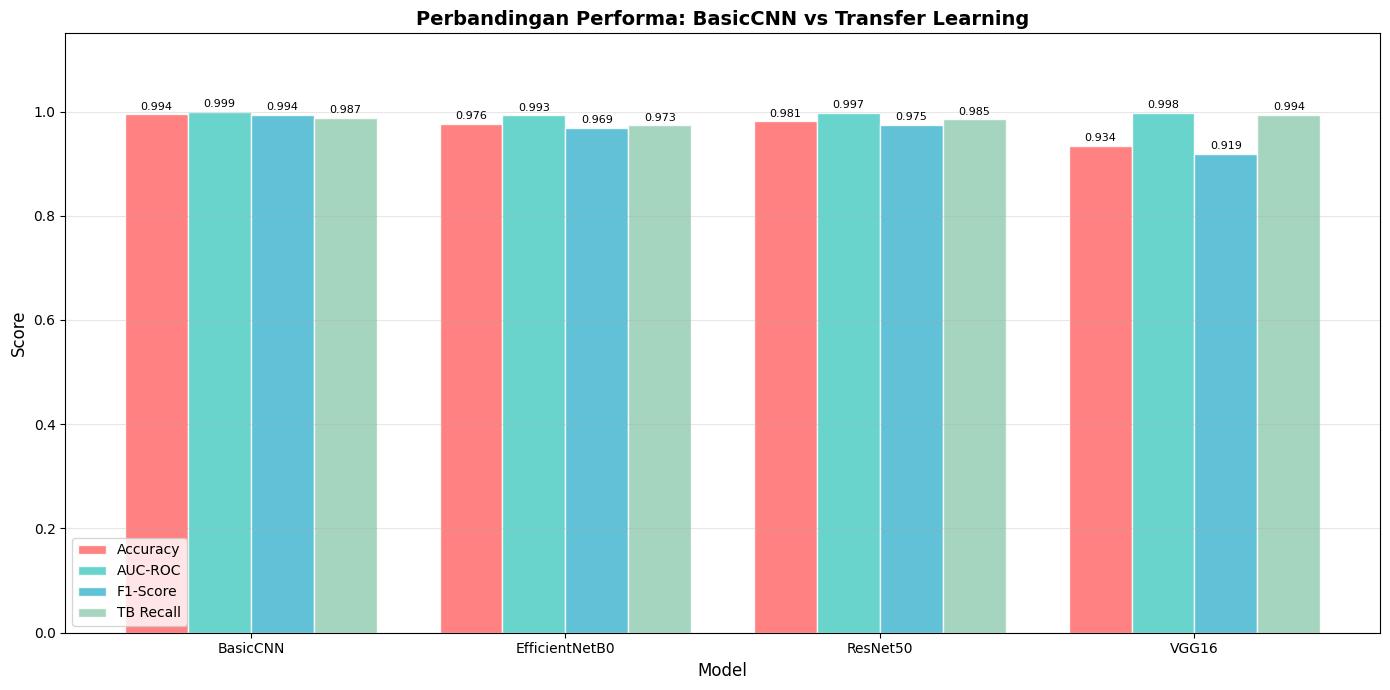

In [40]:
# ============================================================
# 8.1 Load Hasil Transfer Learning & Bandingkan
# ============================================================

# Load evaluation report dari notebook TL
tl_report_path = OUTPUT_DIR / 'evaluation_report.json'

if tl_report_path.exists():
    with open(tl_report_path, 'r') as f:
        tl_report = json.load(f)
    
    tl_results = tl_report.get('results_per_architecture', {})
    
    print('Perbandingan Performa Model:')
    print('=' * 80)
    print(f'{"Model":<20} {"Accuracy":>10} {"AUC-ROC":>10} {"F1":>10} {"TB Recall":>12} {"TB Precision":>14}')
    print('-' * 80)
    
    # BasicCNN results
    print(f'{"BasicCNN":<20} {acc:>10.4f} {roc_auc_val:>10.4f} {f1:>10.4f} '
          f'{cr["TB"]["recall"]:>12.4f} {cr["TB"]["precision"]:>14.4f}')
    
    # TL results
    for arch_name, metrics in tl_results.items():
        star = ' ★' if arch_name == tl_report.get('best_architecture', '') else ''
        print(f'{arch_name + star:<20} {metrics["accuracy"]:>10.4f} {metrics["auc_roc"]:>10.4f} '
              f'{metrics["f1"]:>10.4f} {metrics["recall_tb"]:>12.4f} {metrics["precision_tb"]:>14.4f}')
    
    print('=' * 80)
    print('★ = Model terbaik dari notebook Transfer Learning')
    
    # Bar chart comparison
    model_names = ['BasicCNN'] + list(tl_results.keys())
    metrics_compare = {
        'Accuracy': [acc] + [tl_results[a]['accuracy'] for a in tl_results],
        'AUC-ROC': [roc_auc_val] + [tl_results[a]['auc_roc'] for a in tl_results],
        'F1-Score': [f1] + [tl_results[a]['f1'] for a in tl_results],
        'TB Recall': [cr['TB']['recall']] + [tl_results[a]['recall_tb'] for a in tl_results],
    }
    
    x = np.arange(len(model_names))
    width = 0.2
    
    fig, ax = plt.subplots(figsize=(14, 7))
    
    colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4']
    
    for i, (metric_name, values) in enumerate(metrics_compare.items()):
        bars = ax.bar(x + i * width, values, width, label=metric_name, 
                      color=colors[i], alpha=0.85, edgecolor='white')
        # Add value labels
        for bar, val in zip(bars, values):
            ax.text(bar.get_x() + bar.get_width() / 2., bar.get_height() + 0.005,
                    f'{val:.3f}', ha='center', va='bottom', fontsize=8)
    
    ax.set_xlabel('Model', fontsize=12)
    ax.set_ylabel('Score', fontsize=12)
    ax.set_title('Perbandingan Performa: BasicCNN vs Transfer Learning', fontsize=14, fontweight='bold')
    ax.set_xticks(x + width * 1.5)
    ax.set_xticklabels(model_names)
    ax.legend()
    ax.set_ylim(0, 1.15)
    ax.grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    plt.savefig(str(OUTPUT_DIR / 'comparison_basiccnn_vs_tl.png'), dpi=150, bbox_inches='tight')
    plt.show()
    
else:
    print('⚠ File evaluation_report.json tidak ditemukan.')
    print('  Jalankan notebook transfer learning terlebih dahulu untuk perbandingan.')
    print(f'\nHasil BasicCNN (standalone):')
    print(f'  Accuracy    : {acc:.4f}')
    print(f'  AUC-ROC     : {roc_auc_val:.4f}')
    print(f'  F1-Score    : {f1:.4f}')
    print(f'  TB Recall   : {cr["TB"]["recall"]:.4f}')
    print(f'  TB Precision: {cr["TB"]["precision"]:.4f}')


---
## 9. Model Export & Kesimpulan

In [41]:
# ============================================================
# 9.1 Simpan Model & Artefak Final
# ============================================================

# Simpan model final
final_model_path = str(OUTPUT_DIR / 'tb_cnn_basiccnn_fixed_final.keras')
model.save(final_model_path)
print(f'✓ Model BasicCNN disimpan: {final_model_path}')

# Simpan training history
hist_path = str(OUTPUT_DIR / 'history_BasicCNN_fixed.json')
hist_serializable = {
    k: [float(v) for v in vals] for k, vals in history.history.items()
}
with open(hist_path, 'w') as f:
    json.dump(hist_serializable, f, indent=2)
print(f'✓ Training history disimpan: {hist_path}')

# Simpan evaluation report BasicCNN
eval_report_basic = {
    'model': 'BasicCNN',
    'optimal_threshold': float(optimal_threshold),
    'results': {
        'accuracy': float(acc),
        'auc_roc': float(roc_auc_val),
        'auc_pr': float(pr_auc_val),
        'f1': float(f1),
        'precision_tb': float(cr['TB']['precision']),
        'recall_tb': float(cr['TB']['recall']),
        'precision_normal': float(cr['Normal']['precision']),
        'recall_normal': float(cr['Normal']['recall']),
    },
    'config': {
        'img_size': list(IMG_SIZE),
        'batch_size': BATCH_SIZE,
        'epochs_trained': len(history.history['loss']),
        'epochs_max': EPOCHS,
        'learning_rate': LEARNING_RATE,
        'random_seed': RANDOM_SEED,
        'architecture': 'BasicCNN (4 Conv Blocks, no Transfer Learning)',
    }
}
with open(str(OUTPUT_DIR / 'evaluation_report_basiccnn_fixed.json'), 'w') as f:
    json.dump(eval_report_basic, f, indent=2)
print(f'✓ Evaluation report disimpan')

# List outputs
print(f'\nFile di {OUTPUT_DIR}:')
for fpath in sorted(OUTPUT_DIR.iterdir()):
    if 'basiccnn' in fpath.name.lower() or 'BasicCNN' in fpath.name:
        size_kb = fpath.stat().st_size / 1024
        print(f'  ★ {fpath.name} ({size_kb:.1f} KB)')


✓ Model BasicCNN disimpan: c:\Users\Monk\Downloads\Deteksi Tuberkulosis (TB)\outputs\tb_cnn_basiccnn_fixed_final.keras
✓ Training history disimpan: c:\Users\Monk\Downloads\Deteksi Tuberkulosis (TB)\outputs\history_BasicCNN_fixed.json
✓ Evaluation report disimpan

File di c:\Users\Monk\Downloads\Deteksi Tuberkulosis (TB)\outputs:
  ★ augmentation_samples_basiccnn.png (26.9 KB)
  ★ best_BasicCNN.keras (12361.9 KB)
  ★ best_BasicCNN2.keras (15083.2 KB)
  ★ best_BasicCNN_fixed.keras (6205.2 KB)
  ★ best_BasicCNN_v2.keras (12361.9 KB)
  ★ comparison_basiccnn_vs_tl.png (58.0 KB)
  ★ confusion_matrix_basiccnn.png (42.7 KB)
  ★ evaluation_report_basiccnn_fixed.json (0.6 KB)
  ★ history_BasicCNN_fixed.json (4.9 KB)
  ★ learning_curves_basiccnn.png (192.8 KB)
  ★ preprocessed_samples_basiccnn.png (1245.1 KB)
  ★ roc_pr_curves_basiccnn.png (74.2 KB)
  ★ tb_cnn_basiccnn_fixed_final.keras (12361.1 KB)
  ★ threshold_optimization_basiccnn.png (70.0 KB)


In [42]:
# ============================================================
# 9.2 Kesimpulan
# ============================================================

print('=' * 70)
print('KESIMPULAN — BasicCNN (Tanpa Transfer Learning)')
print('=' * 70)
print()
print('1. ARSITEKTUR MODEL')
print('-' * 40)
print('   4 Convolutional Blocks:')
print('     Block 1: Conv(32)  → BN → ReLU → MaxPool(2,2)')
print('     Block 2: Conv(64)  → BN → ReLU → MaxPool(2,2)')
print('     Block 3: Conv(128) → BN → ReLU → MaxPool(2,2)')
print('     Block 4: Conv(256) → BN → ReLU → MaxPool(2,2)')
print('   Classifier:')
print('     AdaptiveAvgPool(2×2) → 1024-dim')
print('     Dense(512) → Dropout(0.5)')
print('     Dense(256) → Dropout(0.4)')
print('     Dense(2)   → Softmax')
print()
print('2. PERFORMA')
print('-' * 40)
print(f'   Accuracy       : {acc:.4f}')
print(f'   AUC-ROC        : {roc_auc_val:.4f}')
print(f'   F1-Score       : {f1:.4f}')
print(f'   TB Recall      : {cr["TB"]["recall"]:.4f}')
print(f'   TB Precision   : {cr["TB"]["precision"]:.4f}')
print(f'   Optimal Thresh : {optimal_threshold:.2f}')
print(f'   Epochs trained : {len(history.history["loss"])}')
print()
print('3. PERBANDINGAN DENGAN TRANSFER LEARNING')
print('-' * 40)

tl_report_path = OUTPUT_DIR / 'evaluation_report.json'
if tl_report_path.exists():
    with open(tl_report_path, 'r') as f:
        tl_report = json.load(f)
    best_tl = tl_report.get('best_architecture', 'N/A')
    best_tl_metrics = tl_report.get('results_per_architecture', {}).get(best_tl, {})
    
    print(f'   BasicCNN AUC    : {roc_auc_val:.4f}')
    print(f'   {best_tl} AUC : {best_tl_metrics.get("auc_roc", 0):.4f} (best TL)')
    
    diff = roc_auc_val - best_tl_metrics.get('auc_roc', 0)
    if diff >= 0:
        print(f'   → BasicCNN lebih baik +{diff:.4f} AUC')
    else:
        print(f'   → Transfer Learning lebih baik +{abs(diff):.4f} AUC')
else:
    print('   (Data TL tidak tersedia untuk perbandingan)')

print()
print('4. TEMUAN')
print('-' * 40)
print(f'   False Negatives (TB missed)   : {fn_mask.sum()}')
print(f'   False Positives               : {fp_mask.sum()}')
print(f'   Total parameters              : {model.count_params():,}')
print()
print('5. CATATAN')
print('-' * 40)
print('   - Model CNN dasar tanpa pretrained weights')
print('   - Semua parameter dilatih dari scratch')
print('   - Menggunakan data split yang sama untuk fair comparison')
print('   - Output Softmax (2 kelas) dengan SparseCategoricalCrossentropy')
print()
print('=' * 70)
print('END OF NOTEBOOK')
print('=' * 70)


KESIMPULAN — BasicCNN (Tanpa Transfer Learning)

1. ARSITEKTUR MODEL
----------------------------------------
   4 Convolutional Blocks:
     Block 1: Conv(32)  → BN → ReLU → MaxPool(2,2)
     Block 2: Conv(64)  → BN → ReLU → MaxPool(2,2)
     Block 3: Conv(128) → BN → ReLU → MaxPool(2,2)
     Block 4: Conv(256) → BN → ReLU → MaxPool(2,2)
   Classifier:
     AdaptiveAvgPool(2×2) → 1024-dim
     Dense(512) → Dropout(0.5)
     Dense(256) → Dropout(0.4)
     Dense(2)   → Softmax

2. PERFORMA
----------------------------------------
   Accuracy       : 0.9945
   AUC-ROC        : 0.9990
   F1-Score       : 0.9937
   TB Recall      : 0.9875
   TB Precision   : 1.0000
   Optimal Thresh : 0.01
   Epochs trained : 17

3. PERBANDINGAN DENGAN TRANSFER LEARNING
----------------------------------------
   BasicCNN AUC    : 0.9990
   VGG16 AUC : 0.9979 (best TL)
   → BasicCNN lebih baik +0.0011 AUC

4. TEMUAN
----------------------------------------
   False Negatives (TB missed)   : 6
   False Posi